# Ticha HTR — TrOCR with a Zapotec decoder, augmented lines and a regularized CTC encoder

This notebook is `ticha_trocr_finetuning-modified-transformer-aug.ipynb` (the decoupled model trained with augmented lines) with one change: **Part 2 regularizes the CTC encoder**, which overfits in both earlier runs (without augmentation: train CER 0.3% vs validation 24.0% after 10 epochs; with augmentation the gap is 13 points by epoch 3).

**First attempt (stopped).** All three changes below at once made the encoder **underfit**: after 2 epochs, train CER 0.85 and validation CER 0.86, with CTC loss 3.35 → 2.78 (the augmented run without them: loss 1.48, train CER 0.19, validation CER 0.27 after one epoch). It never left CTC's blank-only phase. Since the three changes were made together, that run can't tell which one caused it.

**So Part 2 now starts with an ablation:** each variant below trains for `ABLATION_STEPS` steps on the augmented lines, with the full run's learning-rate schedule, and is scored on the validation lines. Then the variants worth a full run are listed in `CTC_FULL_RUNS` (now D, pooled head, and E, BiLSTM head); each trains for the full Part 2 schedule and the one with the lower validation CER is used from Part 3 on. The ablation catches variants that break early learning; it can't show which variant generalizes best after 10 epochs, because regularization pays off late. Among variants that learn about as fast as the reference, prefer the more regularized one.

The three changes tried in the first attempt:

| Setting | Earlier runs | Here | Why |
|---|---|---|---|
| CTC head (`CTC_HEAD`) | each column's 24 patches concatenated (18,432 values) → 512 → slots: **9.4M** new parameters, a separate weight for every row position | attention pooling over the rows of each column (768 values) → 256 → slots: **about 0.3M** | The flat head can memorize where ink sits in each line; the pooled one has to rely on what the encoder recognizes. |
| Dropout (`CTC_ENCODER_DROPOUT`, `CTC_HEAD_DROPOUT`) | ViT: **0.0** everywhere (the checkpoint ships without dropout); head: 0.1 | ViT: 0.1 (hidden states and attention); head: 0.3 | Randomly turns off units during training, so the encoder can't depend on any single feature. Only during CTC training: the bridge builds its own model with the checkpoint's settings, as before. |
| Frozen layers (`CTC_FROZEN_LAYERS`) | all 12 ViT layers train | the patch embeddings and the **lower 6 layers** stay as pretrained; the upper 6 train | Fewer trainable parameters (about 43M instead of 87M). The lower layers hold generic stroke and shape features that the small dataset doesn't need to change. |

Ablation variants (`CTC_VARIANTS`; add combinations, e.g. B + C, as new entries):

| Variant | Head | Head dropout | ViT dropout | Frozen layers |
|---|---|---|---|---|
| A | flat (9.7M) | 0.1 | 0.0 | 0 |
| B | flat | 0.1 | **0.1** | 0 |
| C | flat | 0.1 | 0.0 | **6** |
| D | **pooled** (0.3M) | 0.1 | 0.0 | 0 |
| E | **BiLSTM** over the 24 columns (about 1M): row average per column, then a bidirectional LSTM, the usual CRNN head for CTC, small but with context from neighbouring columns | 0.1 | 0.0 | 0 |

A is the augmented run's encoder (the reference).

Also: Part 2 stops after `CTC_PATIENCE = 3` epochs without a better validation CER, to save time. The best epoch is kept as before, so this only skips epochs that wouldn't have been chosen unless validation improved again late.

Everything else is unchanged from the augmented notebook: same augmented train lines, same epochs and learning rates, same bridge (Part 3), text decoders reused from the run without augmentation, Part 4 off by default, Part 5 retrained (its noise follows the encoder's CER). `CTC_FULL_RUNS = ['A flat head, no regularization']` reproduces the augmented run's encoder.

**Run the ablation, choose `CTC_FULL_RUNS`, then check Part 2 before running Part 3.** The bridges take hours; they are only worth running if the encoder's best validation CER is clearly below the augmented run's. The comparison at the end shows all three runs (without augmentation, with augmentation, with augmentation and regularization).

Outputs go to `~/ticha-runs/trocr-modified-aug-reg/` on the VM (or `$TICHA_OUTPUT_DIR` + `-aug-reg`), and `MyDrive/TichaHTR/trocr-modified-aug-reg` in Colab. Run it after the augmented notebook has finished, so they don't share the GPU.

**Research note:** This uses TrOCR because the dataset provides image/text line pairs directly. Your project report names Kraken as the main framework, so treat this as the TrOCR experiment/comparison rather than the Kraken run.

## Why this notebook replaced the augmentation-only run

`ticha_trocr_finetuning-modified-transformer-aug.ipynb` (the same decoupled model, augmented lines, the original flat CTC head, no regularization) was stopped during Part 2 and later removed. Its CTC encoder, per epoch (train CER on 500 train lines / validation CER):

| Epoch | Augmentation only (flat head, A) | D pooled head | E BiLSTM head |
|---|---|---|---|
| 1 | 0.192 / 0.273 | 0.207 / 0.274 | 0.263 / 0.313 |
| 2 | 0.132 / 0.239 | 0.137 / 0.233 | 0.154 / 0.234 |
| 3 | 0.098 / 0.229 | 0.101 / 0.217 | 0.113 / 0.217 |
| 10 (best) | not run | 0.007 / 0.198 | 0.013 / 0.194 |

**The problem:** the train/validation gap grew every epoch (8 → 11 → 13 points), as in the run without augmentation, which ended at train CER 0.3% against validation 24.0%. The TrOCR ViT checkpoint has no dropout at all, and the flat head has 9.4M parameters with a separate weight for every row position, so the encoder can memorize where ink sits in each training line.

**What was tried:** all three regularizers at once (pooled head, dropout 0.1 in the ViT and 0.3 in the head, 6 frozen layers) underfit: CER 0.81–0.86 after two epochs, stuck in CTC's blank phase. The one-change-at-a-time ablation then showed that ViT dropout (B) and frozen layers (C) slow learning a lot, while the smaller heads (D pooled, E BiLSTM) learn about as fast as A with a narrower gap. D and E got full runs; E won (validation CER 0.194) and is the encoder of Parts 3–5.

**How much regularization itself helped:** little. At epoch 3 the regularized heads are about 1 point better than the augmentation-only encoder (0.217 against 0.229), and the augmentation-only run never reached epoch 10, so its final value is unknown. Most of the gain over the run without augmentation (validation 0.240 → 0.194, test without Za687 0.213 → 0.173 for the CTC encoder) comes from augmentation. The heads still overfit by epoch 10 (train CER 0.7–1.3%), but validation CER kept improving slowly, so the best epoch was the last one.


In [1]:
import sys
IN_COLAB = 'google.colab' in sys.modules

# The VM's kernel already has these installed; Colab needs them on every new runtime.
if IN_COLAB:
    %pip -q install "transformers==4.46.3" "datasets>=2.19,<4" "accelerate>=0.26" "jiwer>=3.0"

In [2]:
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

import os
# The dataloader workers fork after the tokenizer has run; this avoids a warning per worker.
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')
import numpy as np
import torch
from datasets import load_dataset
from IPython.display import display

print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

ds = load_dataset('maclenn77/ticha-htr-lines', 'original')
print(ds)
for split_name, split_data in ds.items():
    print(f'{split_name}: {len(split_data):,} rows; columns={split_data.column_names}')

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.9.1+cu129
CUDA available: True
GPU: NVIDIA L4


DatasetDict({
    train: Dataset({
        features: ['id', 'image', 'text', 'doc_id', 'page', 'line', 'language', 'source', 'year', 'town', 'doc_type', 'document_url'],
        num_rows: 5786
    })
    validation: Dataset({
        features: ['id', 'image', 'text', 'doc_id', 'page', 'line', 'language', 'source', 'year', 'town', 'doc_type', 'document_url'],
        num_rows: 819
    })
    test: Dataset({
        features: ['id', 'image', 'text', 'doc_id', 'page', 'line', 'language', 'source', 'year', 'town', 'doc_type', 'document_url'],
        num_rows: 1066
    })
})
train: 5,786 rows; columns=['id', 'image', 'text', 'doc_id', 'page', 'line', 'language', 'source', 'year', 'town', 'doc_type', 'document_url']
validation: 819 rows; columns=['id', 'image', 'text', 'doc_id', 'page', 'line', 'language', 'source', 'year', 'town', 'doc_type', 'document_url']
test: 1,066 rows; columns=['id', 'image', 'text', 'doc_id', 'page', 'line', 'language', 'source', 'year', 'town', 'doc_type', 'docume

In [3]:
# Audit the existing split by document. Shared doc_id values would make evaluation unreliable.
required_columns = {'image', 'text', 'doc_id'}
for split_name, split_data in ds.items():
    missing = required_columns - set(split_data.column_names)
    if missing:
        raise ValueError(f'{split_name} is missing required columns: {missing}')

doc_sets = {
    name: {str(x) for x in data['doc_id'] if x is not None}
    for name, data in ds.items()
}
overlaps = {
    'train-validation': doc_sets['train'] & doc_sets['validation'],
    'train-test': doc_sets['train'] & doc_sets['test'],
    'validation-test': doc_sets['validation'] & doc_sets['test'],
}
for pair, shared_docs in overlaps.items():
    print(f'{pair} shared document IDs: {len(shared_docs)}')
    if shared_docs:
        print('Examples:', list(sorted(shared_docs))[:10])

for split_name, split_data in ds.items():
    missing_doc_ids = sum(x is None for x in split_data['doc_id'])
    print(f'{split_name}: rows without doc_id = {missing_doc_ids}')

if any(overlaps.values()):
    print('WARNING: document leakage detected. Do not train until document-level splits are fixed.')
else:
    print('Good: no shared non-null document IDs were found across splits.')


train-validation shared document IDs: 0
train-test shared document IDs: 0
validation-test shared document IDs: 0
train: rows without doc_id = 0
validation: rows without doc_id = 0
test: rows without doc_id = 0
Good: no shared non-null document IDs were found across splits.


Sample text: 'exChij beo de o'
Document: An740 | language: Zapotec | source: auto


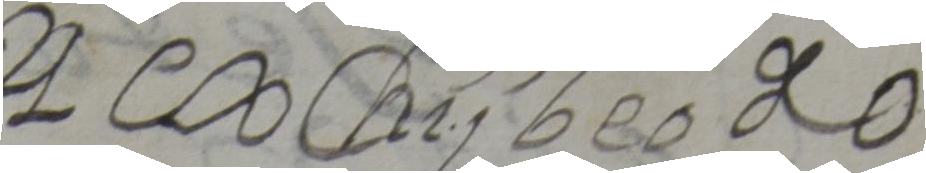

train: empty texts=0, p50=49 chars, p95=67 chars, max=113
validation: empty texts=0, p50=50 chars, p95=67 chars, max=164
test: empty texts=0, p50=48 chars, p95=62 chars, max=82


In [4]:
# Inspect one sample and the transcription-length distribution.
sample = ds['train'][0]
print('Sample text:', repr(sample['text']))
print('Document:', sample['doc_id'], '| language:', sample.get('language'), '| source:', sample.get('source'))
display(sample['image'].convert('RGB'))

for split_name, split_data in ds.items():
    lengths = np.array([len(str(t or '').strip()) for t in split_data['text']])
    print(f"{split_name}: empty texts={(lengths == 0).sum()}, p50={np.percentile(lengths, 50):.0f} chars, p95={np.percentile(lengths, 95):.0f} chars, max={lengths.max()}")


## Clean transcriber notes

The transcriptions mark expansions, glosses and damage with `[]` and `()`. This cell turns them into diplomatic text (what is written on the page) and drops lines whose image and text don't match. Uncertain readings such as `(Santigo?)` are kept as text in train and dropped from validation and test, so the reported CER is on confident transcriptions only (state this in the report). It changes the text only for this experiment: the Hub dataset stays as published, and the original text is kept in `text_raw`.

Run it before the baseline so the baseline, the fine-tuned model and later experiments are all evaluated on the same cleaned test set.

In [5]:
# Transcriber notes: make the text match what is written on the page (diplomatic transcription).
# The transcriptions use [] and () for three things:
#   - abbreviation expansions, p[es]os, to[mine]s, Dom(ing)o: the bracketed letters are not written,
#     so they are deleted (p[es]os -> pos)
#   - glosses, [=Juan]: not on the page, deleted
#   - damage, illegible text and editorial notes, [cortado], [roto], [xxx], [...], [?], [n?],
#     [margin note], (?), (word?): the image has ink the text doesn't cover, so the whole line is dropped
#   - uncertain readings, (Santigo?): the letters are on the page but the transcriber wasn't sure.
#     In train they are kept as text (Santigo); in validation and test the line is dropped, so
#     evaluation uses only confident transcriptions.
# Lines with unbalanced or nested brackets are dropped too.
import re

BRACKET_RE = re.compile(r'\[([^\[\]]*)\]|\(([^()]*)\)')
NOTE_RE = re.compile(
    r'[?…]|^\.+$|\.\.|\s|,|^x+$|^word$'                   # uncertain, illegible, or a note with spaces
    r'|cortado|roto|torn|mancha|borrado|firmas|ilegible',  # damage and editorial notes
    re.IGNORECASE)
DROP_HASH = True  # '#' marks illegible characters in some documents
KEEP_GUESSES_IN_TRAIN = True
GUESS_RE = re.compile(r'\((?!word\?)([^()?]*[^\W\d_][^()?]*)\?+\)')  # (letters?) but not (word?)


def clean_text(text, keep_guesses=False):
    """Return the diplomatic text, or None when the line should be dropped."""
    text = str(text or '')
    if keep_guesses:
        text = GUESS_RE.sub(lambda m: m.group(1), text)
    notes = [square or round for square, round in BRACKET_RE.findall(text)]
    if any(NOTE_RE.search(note.strip()) for note in notes if not note.strip().startswith('=')):
        return None
    text = BRACKET_RE.sub('', text)
    if re.search(r'[\[\]()]', text) or (DROP_HASH and '#' in text):
        return None
    return re.sub(r'\s+', ' ', text).strip() or None


def clean_batch(texts, keep_guesses):
    return {'text_raw': texts, 'text': [clean_text(t, keep_guesses) for t in texts]}

for split_name in ds:
    before = len(ds[split_name])
    keep_guesses = KEEP_GUESSES_IN_TRAIN and split_name == 'train'
    # input_columns keeps the images from being decoded.
    ds[split_name] = ds[split_name].map(clean_batch, input_columns='text', batched=True,
                                        fn_kwargs={'keep_guesses': keep_guesses})
    ds[split_name] = ds[split_name].filter(lambda t: t is not None, input_columns='text')
    changed = sum(raw != text for raw, text in zip(ds[split_name]['text_raw'], ds[split_name]['text']))
    print(f'{split_name}: kept {len(ds[split_name]):,} / {before:,} lines '
          f'(dropped {before - len(ds[split_name]):,}, cleaned text in {changed:,})')

examples = [(r, t) for r, t in zip(ds['train']['text_raw'], ds['train']['text']) if r != t][:5]
for raw, text in examples:
    print(f'{raw!r}\n  -> {text!r}')


train: kept 5,305 / 5,786 lines (dropped 481, cleaned text in 370)


validation: kept 710 / 819 lines (dropped 109, cleaned text in 58)
test: kept 973 / 1,066 lines (dropped 93, cleaned text in 69)
'Ana chi Sabado gola bixiopa Xiche beo Mayo ysa de 1731 a[ño]s'
  -> 'Ana chi Sabado gola bixiopa Xiche beo Mayo ysa de 1731 as'
'yoo lahui latena chiba Corona Xitini D[io] s , huane Reiy'
  -> 'yoo lahui latena chiba Corona Xitini D s , huane Reiy'
'layoo nirini nibitona lau tono Justisia huane lau to(no)'
  -> 'layoo nirini nibitona lau tono Justisia huane lau to'
'testigos guichi escriptura de venta ni pene nicolas (be)'
  -> 'testigos guichi escriptura de venta ni pene nicolas'
'launa Justisia Antonio de Santia(go)'
  -> 'launa Justisia Antonio de Santia'


## Remove train documents that duplicate evaluation documents

Ticha lists some manuscripts twice. **Th687 (train) and Za687 (test) are the same pages**, scanned twice and transcribed the same way, so without this step the test split would score lines the model was trained on. A train document is dropped when more than half of its lines appear verbatim in validation or test.

Original/translation pairs (`Al710` and `Al710T`) are different manuscripts in different languages, but they share names, places and dates. They are kept by default (about 10% of the train lines); set `DROP_TRANSLATION_PAIRS = True` to drop the train half of each pair and report both numbers if the difference matters.

In [6]:
DUPLICATE_SHARE = 0.5
DROP_TRANSLATION_PAIRS = False


def line_key(text):
    return re.sub(r'\W+', ' ', text.lower()).strip()


def base_id(doc_id):
    return doc_id[:-1] if doc_id.endswith('T') else doc_id


eval_keys = {line_key(text) for split_name in ('validation', 'test')
             for text in ds[split_name]['text'] if len(text) >= 15}
train_lines_by_doc = {}
for doc_id, text in zip(ds['train']['doc_id'], ds['train']['text']):
    train_lines_by_doc.setdefault(doc_id, []).append(text)
duplicate_docs = {doc_id for doc_id, texts in train_lines_by_doc.items()
                  if sum(line_key(t) in eval_keys for t in texts) > DUPLICATE_SHARE * len(texts)}
eval_bases = {base_id(d) for split_name in ('validation', 'test') for d in set(ds[split_name]['doc_id'])}
pair_docs = {doc_id for doc_id in train_lines_by_doc if base_id(doc_id) in eval_bases}

print('Train documents duplicating validation/test documents (dropped):', sorted(duplicate_docs))
print(f"Train documents paired with a validation/test translation: {len(pair_docs)} "
      f"({sum(len(train_lines_by_doc[d]) for d in pair_docs)} lines), "
      f"{'dropped' if DROP_TRANSLATION_PAIRS else 'kept'}")
drop_docs = duplicate_docs | (pair_docs if DROP_TRANSLATION_PAIRS else set())
before = len(ds['train'])
ds['train'] = ds['train'].filter(lambda doc_id: doc_id not in drop_docs, input_columns='doc_id')
print(f"train: kept {len(ds['train']):,} / {before:,} lines")

Train documents duplicating validation/test documents (dropped): ['Th687']
Train documents paired with a validation/test translation: 11 (544 lines), kept
train: kept 5,268 / 5,305 lines


## Augmented train lines

The augmented copies of the train lines, cleaned like the originals, and without the documents dropped above (Th687). `train_aug` is used only by the stages that see images (Parts 2, 3 and 4.2). The text corpora in Part 1 are built from the original lines only, so the copies don't repeat each line's text five times.

In [7]:
from datasets import concatenate_datasets

aug = load_dataset('maclenn77/ticha-htr-lines', 'augmented')['train']
before = len(aug)
aug = aug.filter(lambda doc_id: doc_id not in drop_docs, input_columns='doc_id')
aug = aug.map(clean_batch, input_columns='text', batched=True, fn_kwargs={'keep_guesses': KEEP_GUESSES_IN_TRAIN})
aug = aug.filter(lambda t: t is not None, input_columns='text')
shared_columns = [c for c in ds['train'].column_names if c in aug.column_names]
aug = aug.select_columns(shared_columns).cast(ds['train'].select_columns(shared_columns).features)
train_aug = concatenate_datasets([ds['train'].select_columns(shared_columns), aug]).shuffle(seed=42)
assert not set(train_aug['doc_id']) & {d for split in ('validation', 'test') for d in ds[split]['doc_id']}
print(f'augmented: kept {len(aug):,} / {before:,} lines; train with augmentation: {len(train_aug):,} lines '
      f'({len(train_aug) / len(ds["train"]):.1f}x the original train set)')

augmented: kept 21,072 / 23,144 lines; train with augmentation: 26,340 lines (5.0x the original train set)


## Load the pretrained TrOCR model

The base handwritten checkpoint is the starting point for the baseline and for both halves of the modified model. `configure_trocr` sets the token ids and generation settings; it is reused when the modified models are assembled.

In [8]:
from transformers import TrOCRProcessor, VisionEncoderDecoderModel

MODEL_ID = 'microsoft/trocr-base-handwritten'
processor = TrOCRProcessor.from_pretrained(MODEL_ID)
model = VisionEncoderDecoderModel.from_pretrained(MODEL_ID)

# Select a target length based on the training transcription distribution.
train_texts = [str(t or '').strip() for t in ds['train']['text']]
token_lengths = [len(processor.tokenizer(t, add_special_tokens=True).input_ids) for t in train_texts]
p99_tokens = int(np.percentile(token_lengths, 99))
MAX_TARGET_LENGTH = min(256, max(64, p99_tokens + 8))
truncated_count = sum(length > MAX_TARGET_LENGTH for length in token_lengths)
print('99th percentile token length:', p99_tokens)
print('MAX_TARGET_LENGTH:', MAX_TARGET_LENGTH)
print('Training lines longer than this limit:', truncated_count, '/', len(token_lengths))


def configure_trocr(model):
    """Token ids and generation settings shared by the baseline and the modified models."""
    model.config.decoder_start_token_id = processor.tokenizer.cls_token_id
    model.config.pad_token_id = processor.tokenizer.pad_token_id
    model.config.eos_token_id = processor.tokenizer.sep_token_id
    model.config.vocab_size = model.config.decoder.vocab_size
    # generate() reads generation_config, which the checkpoint ships with decoder_start_token_id=2 (</s>)
    model.generation_config.decoder_start_token_id = model.config.decoder_start_token_id
    model.generation_config.pad_token_id = model.config.pad_token_id
    model.generation_config.eos_token_id = model.config.eos_token_id
    model.generation_config.max_length = MAX_TARGET_LENGTH
    model.generation_config.num_beams = 2
    model.generation_config.early_stopping = True
    return model


configure_trocr(model)
print('Loaded:', MODEL_ID)

Config of the encoder: <class 'transformers.models.vit.modeling_vit.ViTModel'> is overwritten by shared encoder config: ViTConfig {
  "attention_probs_dropout_prob": 0.0,
  "encoder_stride": 16,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 768,
  "image_size": 384,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "model_type": "vit",
  "num_attention_heads": 12,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "patch_size": 16,
  "qkv_bias": false,
  "transformers_version": "4.46.3"
}



Config of the decoder: <class 'transformers.models.trocr.modeling_trocr.TrOCRForCausalLM'> is overwritten by shared decoder config: TrOCRConfig {
  "activation_dropout": 0.0,
  "activation_function": "gelu",
  "add_cross_attention": true,
  "attention_dropout": 0.0,
  "bos_token_id": 0,
  "classifier_dropout": 0.0,
  "cross_attention_hidden_size": 768,
  "d_model": 1024,
  "decoder_attention_heads": 16,
  "decoder_ffn_dim": 4096,
  "decoder_layerdrop": 0.0,
  "decoder_layers": 12,
  "decoder_start_token_id": 2,
  "dropout": 0.1,
  "eos_token_id": 2,
  "init_std": 0.02,
  "is_decoder": true,
  "layernorm_embedding": true,
  "max_position_embeddings": 512,
  "model_type": "trocr",
  "pad_token_id": 1,
  "scale_embedding": false,
  "transformers_version": "4.46.3",
  "use_cache": false,
  "use_learned_position_embeddings": true,
  "vocab_size": 50265
}



Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-base-handwritten and are newly initialized: ['encoder.pooler.dense.bias', 'encoder.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


99th percentile token length: 32
MAX_TARGET_LENGTH: 64
Training lines longer than this limit: 0 / 5268
Loaded: microsoft/trocr-base-handwritten


In [9]:
# Process images in each batch to avoid storing all image tensors in RAM.
class TrOCRDataCollator:
    def __init__(self, processor, max_target_length):
        self.processor = processor
        self.max_target_length = max_target_length

    def __call__(self, batch):
        images = [item['image'].convert('RGB') for item in batch]
        pixel_values = self.processor(images=images, return_tensors='pt').pixel_values
        texts = [str(item['text'] or '').strip() for item in batch]
        labels = self.processor.tokenizer(
            texts,
            padding='max_length',
            max_length=self.max_target_length,
            truncation=True,
            return_tensors='pt'
        ).input_ids
        labels[labels == self.processor.tokenizer.pad_token_id] = -100
        return {'pixel_values': pixel_values, 'labels': labels}

data_collator = TrOCRDataCollator(processor, MAX_TARGET_LENGTH)


In [10]:
import json
from jiwer import cer, wer
from transformers import Seq2SeqTrainer, Seq2SeqTrainingArguments, EarlyStoppingCallback
from transformers.trainer_utils import get_last_checkpoint

def compute_metrics(eval_pred):
    pred_ids = eval_pred.predictions
    if isinstance(pred_ids, tuple):
        pred_ids = pred_ids[0]
    label_ids = np.array(eval_pred.label_ids, copy=True)
    label_ids[label_ids == -100] = processor.tokenizer.pad_token_id
    pred_text = processor.batch_decode(pred_ids, skip_special_tokens=True)
    ref_text = processor.batch_decode(label_ids, skip_special_tokens=True)
    pred_text = [text.strip() for text in pred_text]
    ref_text = [text.strip() for text in ref_text]
    return {'cer': cer(ref_text, pred_text), 'wer': wer(ref_text, pred_text)}

# Guard against accidental CPU training or document leakage.
if any(overlaps.values()):
    raise RuntimeError('Document IDs overlap across splits. Fix document-level splits before training.')
if not torch.cuda.is_available():
    raise RuntimeError('No GPU detected. In Colab choose Runtime > Change runtime type > T4 GPU; on the VM check nvidia-smi. Then rerun cells.')

# DECOUPLED_DIR is the run without augmentation (ticha_trocr_finetuning-modified-transformer.ipynb): its text-only
# models are reused and its results are compared at the end. This notebook writes only to OUTPUT_DIR.
if IN_COLAB:
    DECOUPLED_DIR = '/content/drive/MyDrive/TichaHTR/trocr-modified'
else:
    DECOUPLED_DIR = os.path.expanduser(os.environ.get('TICHA_OUTPUT_DIR', '~/ticha-runs/trocr-modified'))
AUG_DIR = DECOUPLED_DIR.rstrip('/') + '-aug'  # the augmented run with the earlier encoder, compared at the end
OUTPUT_DIR = DECOUPLED_DIR.rstrip('/') + '-aug-reg'
os.makedirs(OUTPUT_DIR, exist_ok=True)
# Every part saves its model to OUTPUT_DIR and, when that file already exists, loads it instead of training
# again. Set RETRAIN = True to train everything from scratch (or delete one part's folder to retrain only it).
RETRAIN = False
curves = {}  # training histories, plotted before the test evaluation


def shared_text_path(*parts):
    """A text-only model's file: the one from the run without augmentation when it exists, otherwise this run's."""
    shared = os.path.join(DECOUPLED_DIR, *parts)
    return shared if os.path.exists(shared) and not RETRAIN else os.path.join(OUTPUT_DIR, *parts)

# Same effective batch size (8) everywhere: 2 x 4 on a 16 GB T4, 8 x 1 on a 23 GB L4.
gpu_memory_gb = torch.cuda.get_device_properties(0).total_memory / 1024**3
BATCH_SIZE = 8 if gpu_memory_gb >= 20 else 2
# bf16 is more stable than fp16 and the L4 (Ada) supports it; the T4 does not.
USE_BF16 = torch.cuda.is_bf16_supported()
AMP_DTYPE = torch.bfloat16 if USE_BF16 else torch.float16
DEVICE = torch.device('cuda')
NUM_WORKERS = 2 if IN_COLAB else 4
print(f'GPU memory: {gpu_memory_gb:.0f} GB | batch size: {BATCH_SIZE} | bf16: {USE_BF16}')


def seq2seq_args(output_dir, **overrides):
    """Arguments shared by the baseline and the bridge runs; overrides add the training schedule."""
    args = dict(
        output_dir=output_dir,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=BATCH_SIZE,
        gradient_accumulation_steps=8 // BATCH_SIZE,
        predict_with_generate=True,
        generation_max_length=MAX_TARGET_LENGTH,
        generation_num_beams=2,
        fp16=not USE_BF16,
        bf16=USE_BF16,
        remove_unused_columns=False,
        dataloader_num_workers=NUM_WORKERS,
        report_to='none',
        seed=42
    )
    args.update(overrides)
    return Seq2SeqTrainingArguments(**args)

# This trainer only generates predictions for the pretrained baseline; nothing is trained with it.
trainer = Seq2SeqTrainer(
    model=model,
    args=seq2seq_args(os.path.join(OUTPUT_DIR, 'baseline')),
    data_collator=data_collator,
    compute_metrics=compute_metrics
)
print('Output:', OUTPUT_DIR)
print('Run without augmentation (text models reused, compared at the end):', DECOUPLED_DIR)

GPU memory: 22 GB | batch size: 8 | bf16: True


Output: /home/paw/ticha-runs/trocr-modified-aug-reg
Run without augmentation (text models reused, compared at the end): /home/paw/ticha-runs/trocr-modified


## Optional: measure the pretrained baseline

Run this cell to get the zero-shot baseline required for your project comparison. It evaluates the original pretrained checkpoint on the test split; do not use the test score to tune hyperparameters. The final cell breaks it down by language next to the modified models.

In [11]:
# Optional; can take several minutes because predictions are generated for the full test set.
baseline_result = trainer.predict(ds['test'], metric_key_prefix='baseline')
print(baseline_result.metrics)
trainer.save_metrics('baseline', baseline_result.metrics)


Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.


Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.


Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.


Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.


Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.


...

Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.


Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.


Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.


Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.


{'baseline_loss': 9.715266227722168, 'baseline_model_preparation_time': 0.01, 'baseline_cer': 0.6957972582972582, 'baseline_wer': 1.0389207258834765, 'baseline_runtime': 81.2429, 'baseline_samples_per_second': 11.976, 'baseline_steps_per_second': 1.502}


## Part 1 — Text-only decoder embeddings (Zapotec and Zapotec + Spanish)

The decoder is trained as a language model, without images, on two corpora:

| Variant | Manuscript lines (train split only) | Printed works |
|---|---|---|
| `zap` | lines from Zapotec documents | lines classified as Zapotec |
| `zap_spa` | all lines | all lines |

Rules:

- Manuscript text comes only from the **train** split, so validation and test transcriptions are never seen. The printed works are separate documents, so they don't leak.
- Printed lines go through the same `clean_text` as the manuscripts plus printed-only fixes: `ſ`→`s` (the manuscript transcriptions use `s`), pilcrows, `|` and `*` markers and private-use glyphs removed, running heads and page numbers dropped, Unicode NFC.
- A printed line counts as Zapotec when at least 70% of its letters are in words a small classifier calls Zapotec. The classifier is a character n-gram naive Bayes over words, trained on Córdova's grammar, where Ticha marks every Zapotec word, and on the manuscript train lines. Spanish, Latin and English lines (front matter, headings, glosses) and mixed lines go only to `zap_spa`. No off-the-shelf language identifier covers Colonial Zapotec spelling.
- Printed text is brought to the manuscripts' character set: accents the manuscripts don't use (Córdova's `à`, `ì`, `ô`) are removed, and lines that still have characters never seen in the train manuscripts (`&`, Latin quotations, `ʒ`) are dropped. Letter-spaced title lines (`A R T E E N L E N`) are dropped, and repeated lines (section headings such as `Preterito perfecto`) are kept once.
- Manuscript lines are repeated `MANUSCRIPT_REPEATS` times so the handwritten-document spelling isn't drowned by the larger printed corpus.
- One example per line, as in the HTR data. Line-final hyphens are kept because the manuscript lines have them too.

In this notebook the decoders are loaded from the run without augmentation when they exist there (`shared_text_path`), so both runs use the same decoders.

In [12]:
import math
import re
import unicodedata
from collections import Counter
import pandas as pd

if IN_COLAB:
    PRINTED_CSV = '/content/drive/MyDrive/TichaHTR/printed.csv'
else:
    # The kernel may start in the repo root (VS Code, the VM's Jupyter service) or in notebooks/train/.
    PRINTED_CSV = os.environ.get('TICHA_PRINTED_CSV') or next(
        (p for p in ['data/printed.csv', '../../data/printed.csv'] if os.path.exists(p)), 'data/printed.csv')
    PRINTED_CSV = os.path.abspath(os.path.expanduser(PRINTED_CSV))
if not os.path.exists(PRINTED_CSV):
    raise FileNotFoundError(f'Printed corpus not found at {PRINTED_CSV}; set TICHA_PRINTED_CSV (cwd is {os.getcwd()}).')
print('Printed corpus:', PRINTED_CSV)
MANUSCRIPT_REPEATS = 2

# Printed-only fixes. The manuscripts are transcribed with plain s, so long s is normalized.
PRINTED_FIXES = str.maketrans({'ſ': 's', 'ҫ': 'ç', 'С': 'Ç',
                               '¶': None, '|': None, '¦': None, '*': None, '✠': None, '℞': None})


MANUSCRIPT_CHARS = set(''.join(ds['train']['text']))


def to_manuscript_chars(line):
    """Strip accents the manuscripts don't use; return None if a character still isn't in the manuscripts."""
    chars = []
    for ch in line:
        if ch not in MANUSCRIPT_CHARS:
            ch = ''.join(c for c in unicodedata.normalize('NFD', ch) if unicodedata.category(c) != 'Mn')
            if not ch or any(c not in MANUSCRIPT_CHARS for c in ch):
                return None
        chars.append(ch)
    return ''.join(chars)


def clean_printed_line(line):
    """Return a printed line in the manuscripts' conventions, or None when it should be dropped."""
    line = unicodedata.normalize('NFC', line).translate(PRINTED_FIXES)
    line = ''.join(ch for ch in line if unicodedata.category(ch) != 'Co')  # private-use glyphs
    line = re.sub(r'\s+', ' ', line).strip()
    if any(ch.isdigit() for ch in line) and not any(ch.islower() for ch in line):
        return None  # running heads ('ZAPOTECA 4'), page numbers, printer's signatures
    if len(re.findall(r'[^\W\d_]', line)) < 3:
        return None
    if re.fullmatch(r'(?:\S ){2,}\S[.,]?', line):
        return None  # letter-spaced title lines: 'A R T E E N L E N'
    line = to_manuscript_chars(clean_text(line, keep_guesses=True) or '')
    return line or None


WORD_RE = re.compile(r'[^\W\d_]+')
# A printed line is Zapotec when at least this share of its letters is in Zapotec words. 0.7 keeps Zapotec lines
# with Spanish loanwords (Dios, Santa Maria, gracia) and still lets no Spanish validation line through.
ZAPOTEC_SHARE = 0.7


class WordLanguageModel:
    """Character n-gram naive Bayes over word types: whether a word is Zapotec or Spanish."""

    def __init__(self, words_by_language, n=4, alpha=0.5):
        self.n, self.alpha = n, alpha
        self.counts = {language: Counter(g for w in words for g in self.grams(w))
                       for language, words in words_by_language.items()}
        self.totals = {language: sum(c.values()) for language, c in self.counts.items()}
        self.vocab_size = len(set().union(*self.counts.values()))
        n_words = sum(len(words) for words in words_by_language.values())
        self.prior = {language: math.log(len(words) / n_words) for language, words in words_by_language.items()}

    def grams(self, word):
        word = f'<{word}>'
        return [word[i:i + k] for k in range(1, self.n + 1) for i in range(len(word) - k + 1)]

    def log_score(self, word, language):
        counts, total = self.counts[language], self.totals[language] + self.alpha * self.vocab_size
        return self.prior[language] + sum(math.log((counts[g] + self.alpha) / total) for g in self.grams(word))

    def is_zapotec(self, word):
        return self.log_score(word, 'zap') > self.log_score(word, 'spa')


def words_of(text):
    text = unicodedata.normalize('NFC', text.lower()).translate(PRINTED_FIXES)
    return [w for w in WORD_RE.findall(text) if len(w) >= 2]


printed = pd.read_csv(PRINTED_CSV)

# Labelled words: Ticha marks every Zapotec word in Córdova's grammar, so the rest of his text is Spanish.
# Manuscript train lines add the documents' spelling; words also seen in Spanish documents (names, dates,
# loanwords) are not counted as Zapotec.
zap_words, spa_words = Counter(), Counter()
for page, marked in printed.loc[printed['zapotec_marked'].notna(), ['transcription', 'zapotec_marked']].values:
    marked_words = set(words_of(marked))
    for word in words_of(page):
        (zap_words if word in marked_words else spa_words)[word] += 1
for text, language in zip(ds['train']['text'], ds['train']['language']):
    if language == 'Spanish':
        spa_words.update(words_of(text))
for text, language in zip(ds['train']['text'], ds['train']['language']):
    if language == 'Zapotec':
        zap_words.update(w for w in words_of(text) if w not in spa_words)
word_model = WordLanguageModel({'zap': list(zap_words), 'spa': list(spa_words)})


def is_zapotec_line(line):
    words = words_of(line)
    if len(words) < 2:
        return False
    zapotec_letters = sum(len(w) for w in words if word_model.is_zapotec(w))
    return zapotec_letters >= ZAPOTEC_SHARE * sum(map(len, words))


printed_rows = [(slug, cleaned)
                for slug, page in printed[['slug', 'transcription']].dropna().values
                for line in page.split('\n')
                if (cleaned := clean_printed_line(line))]
seen_lines = set()
printed_rows = [(slug, line) for slug, line in printed_rows if not (line in seen_lines or seen_lines.add(line))]
printed_lines = [line for _, line in printed_rows]
printed_zap = [line for line in printed_lines if is_zapotec_line(line)]

train_pairs = list(zip(ds['train']['text'], ds['train']['language']))
manuscript_zap = [text for text, language in train_pairs if language == 'Zapotec']
manuscript_all = [text for text, _ in train_pairs]

text_corpora = {
    'zap': manuscript_zap * MANUSCRIPT_REPEATS + printed_zap,
    'zap_spa': manuscript_all * MANUSCRIPT_REPEATS + printed_lines,
}
# Validation lines measure how well each decoder predicts unseen manuscript text, per language.
val_pairs = list(zip(ds['validation']['text'], ds['validation']['language']))
lm_eval_texts = {
    'zap': [text for text, language in val_pairs if language == 'Zapotec'],
    'spa': [text for text, language in val_pairs if language != 'Zapotec'],
}

print(f'Printed: {len(printed_lines):,} lines kept, {len(printed_zap):,} classified as Zapotec')
print(f'Manuscript train: {len(manuscript_all):,} lines, {len(manuscript_zap):,} from Zapotec documents')
for name, texts in text_corpora.items():
    print(f'Corpus {name}: {len(texts):,} lines, {sum(map(len, texts)):,} characters')
for name, texts in lm_eval_texts.items():
    print(f'LM validation {name}: {len(texts):,} lines')
# Check the classifier at the start, middle and end of each work: front matter and prologues are often
# in Spanish or Latin, so the first lines alone aren't a fair sample.
SAMPLE_WINDOW = 60
for slug in printed['slug'].unique():
    lines = [line for s, line in printed_rows if s == slug]
    print(f'\n{slug} ({len(lines):,} lines)')
    for part, start in [('start', 0), ('middle', (len(lines) - SAMPLE_WINDOW) // 2),
                        ('end', len(lines) - SAMPLE_WINDOW)]:
        window = lines[max(start, 0):max(start, 0) + SAMPLE_WINDOW]
        zapotec = [line for line in window if is_zapotec_line(line)]
        other = [line for line in window if not is_zapotec_line(line)]
        print(f'  {part}: {len(zapotec)}/{len(window)} classified as Zapotec')
        for line in zapotec[:3]:
            print('     zap |', line)
        for line in other[:2]:
            print('   other |', line)

Printed corpus: /home/paw/ticha/data/printed.csv


Printed: 20,118 lines kept, 9,500 classified as Zapotec
Manuscript train: 5,268 lines, 1,849 from Zapotec documents
Corpus zap: 13,198 lines, 889,271 characters
Corpus zap_spa: 30,654 lines, 1,663,285 characters
LM validation zap: 273 lines
LM validation spa: 437 lines

aguero-miscelaneo (9,219 lines)
  start: 0/60 classified as Zapotec
   other | EX HOC. CO LLIGO
   other | EX-LIBRIS DOCTORIS. N. LEON.
  middle: 55/60 classified as Zapotec
     zap | lachiñaa manni tooxondi, ni rotiia, ni riteeza xooni naa, callaqui
     zap | xoobalij Xtollaya lachiñaa copabiitoo, callacaziia xilla baaneza,
     zap | Xtennilo nacaya, huanonna guelaya yobilo huanapaya quela Cofra-
   other | con-
   other | Sacramento, Xpellalati yoona xinnilo Iesu Christo, chiiba loo be-
  end: 43/60 classified as Zapotec
     zap | huañee xiñaquela huezaa-
     zap | lachi ní racañee, ni rezij, rel-
     zap | laani celij qujiraa benni Chri- stianos chijrallapea quela co-
   other | llamarlo, creerlo, adorarlo, có 

  middle: 15/60 classified as Zapotec
     zap | Xii ticha pegozeeteni loo.
     zap | Ticha, ni rinniiona Doctri -
     zap | Taapa cuee rapani?
   other | R. La Santissima Trinidad.
   other | P. Quien es la Smâ Trinidad?
  end: 46/60 classified as Zapotec
     zap | XIñaalii quellanayaanii,
     zap | Pecuaani annaa quellahuiilla
     zap | Lezaacagaa ni pebaani
   other | Deprecacion â la Santissima Virgen.
   other | Quebaalachina reciilla


### Modified head: restrict the output vocabulary

RoBERTa's 50k tokens are mostly English words that never appear in these documents, and the small HTR dataset can't teach the decoder to avoid all of them. The output projection is replaced by `MaskedLinear`, which adds a fixed `-1e4` to the logits of tokens outside the allowed set:

- every token that occurs in the tokenized `zap_spa` corpus (train manuscripts and printed works, so both variants share one head);
- every token that decodes to a single character or byte, so any string, including unseen Zapotec words, can still be spelled;
- the special tokens.

The weight matrix is the original one (shared with the embeddings if the checkpoint ties them), so the mask only removes options; the embeddings are what Part 1 trains. The mask is a buffer, so it is saved in the state dicts below.

In [13]:
class MaskedLinear(torch.nn.Linear):
    """Output projection with a fixed logit penalty on tokens outside the allowed vocabulary."""

    def __init__(self, linear, allowed_ids, penalty=-1e4):
        super().__init__(linear.in_features, linear.out_features, bias=False, device='meta')
        self.weight = linear.weight  # keeps any tying with the input embeddings
        mask = torch.full((linear.out_features,), penalty, dtype=torch.float32, device=linear.weight.device)
        mask[list(allowed_ids)] = 0.0
        self.register_buffer('vocab_mask', mask)

    def forward(self, x):
        logits = super().forward(x)
        return logits + self.vocab_mask.to(logits.dtype)


def restrict_output_vocab(decoder, allowed_ids):
    if not isinstance(decoder.output_projection, MaskedLinear):
        decoder.output_projection = MaskedLinear(decoder.output_projection, allowed_ids)
    return decoder


def corpus_token_ids(texts, batch_size=1000):
    ids = set()
    for start in range(0, len(texts), batch_size):
        for seq in processor.tokenizer(texts[start:start + batch_size], add_special_tokens=False).input_ids:
            ids.update(seq)
    return ids


tokenizer = processor.tokenizer
single_char_ids = {token_id for token, token_id in tokenizer.get_vocab().items()
                   if len(tokenizer.convert_tokens_to_string([token]).strip()) <= 1}
allowed_ids = sorted(corpus_token_ids(text_corpora['zap_spa']) | single_char_ids | set(tokenizer.all_special_ids))
print(f'Allowed output tokens: {len(allowed_ids):,} / {len(tokenizer):,}')

# How many tokens per word: a rough measure of how well the English BPE fits each language.
for name, texts in lm_eval_texts.items():
    n_tokens = sum(len(seq) for seq in tokenizer(texts, add_special_tokens=False).input_ids)
    n_words = sum(len(text.split()) for text in texts)
    print(f'{name}: {n_tokens / max(n_words, 1):.2f} tokens per word')

Token indices sequence length is longer than the specified maximum sequence length for this model (553 > 512). Running this sequence through the model will result in indexing errors


Allowed output tokens: 7,138 / 50,265
zap: 2.24 tokens per word
spa: 1.81 tokens per word


In [14]:
from datasets import Dataset
from transformers import Trainer, TrainingArguments
from transformers.models.vision_encoder_decoder.modeling_vision_encoder_decoder import shift_tokens_right

DECODER_VARIANTS = ['zap', 'zap_spa']
TEXT_EPOCHS = 3
TEXT_BATCH_SIZE = 32
TEXT_LR = 5e-5


class TextLMCollator:
    """Builds decoder inputs exactly as VisionEncoderDecoderModel does, so the text training matches the HTR task."""

    def __init__(self, tokenizer, max_length, decoder_start_token_id):
        self.tokenizer = tokenizer
        self.max_length = max_length
        self.decoder_start_token_id = decoder_start_token_id

    def __call__(self, batch):
        texts = [item['text'] for item in batch]
        labels = self.tokenizer(texts, padding='longest', max_length=self.max_length,
                                truncation=True, return_tensors='pt').input_ids
        input_ids = shift_tokens_right(labels, self.tokenizer.pad_token_id, self.decoder_start_token_id)
        labels[labels == self.tokenizer.pad_token_id] = -100
        return {'input_ids': input_ids, 'labels': labels}


def text_lm_args(output_dir):
    """Text-only training settings, shared with the character decoders in Part 4."""
    return TrainingArguments(
        output_dir=output_dir,
        per_device_train_batch_size=TEXT_BATCH_SIZE,
        per_device_eval_batch_size=TEXT_BATCH_SIZE,
        learning_rate=TEXT_LR,
        weight_decay=0.01,
        warmup_ratio=0.05,
        num_train_epochs=TEXT_EPOCHS,
        eval_strategy='epoch',
        save_strategy='no',
        logging_steps=100,
        fp16=not USE_BF16,
        bf16=USE_BF16,
        remove_unused_columns=False,
        dataloader_num_workers=NUM_WORKERS,
        report_to='none',
        seed=42
    )


def decoder_path(variant):
    return shared_text_path(f'decoder_{variant}', 'decoder_state.pt')


text_collator = TextLMCollator(tokenizer, MAX_TARGET_LENGTH, processor.tokenizer.cls_token_id)
lm_eval_ds = {name: Dataset.from_dict({'text': texts}) for name, texts in lm_eval_texts.items()}
text_results = {}

for variant in DECODER_VARIANTS:
    history_path = os.path.join(os.path.dirname(decoder_path(variant)), 'history.json')
    if os.path.exists(decoder_path(variant)) and not RETRAIN:
        saved = json.load(open(history_path))
        text_results[variant], curves[f'text {variant}'] = saved['results'], saved['log_history']
        print(f'{variant}: using the saved decoder {decoder_path(variant)}')
        continue
    decoder = VisionEncoderDecoderModel.from_pretrained(MODEL_ID).decoder
    restrict_output_vocab(decoder, allowed_ids)
    # Without images the cross-attention is skipped; freezing it keeps weight decay off it too.
    for name, param in decoder.named_parameters():
        param.requires_grad = 'encoder_attn' not in name

    variant_dir = os.path.dirname(decoder_path(variant))
    text_trainer = Trainer(
        model=decoder,
        args=text_lm_args(variant_dir),
        train_dataset=Dataset.from_dict({'text': text_corpora[variant]}).shuffle(seed=42),
        eval_dataset=lm_eval_ds,
        data_collator=text_collator
    )
    before = text_trainer.evaluate()
    text_trainer.train()
    after = text_trainer.evaluate()
    os.makedirs(variant_dir, exist_ok=True)
    torch.save(text_trainer.model.state_dict(), decoder_path(variant))
    text_results[variant] = {f'{split}_ppl_{when}': float(np.exp(metrics[f'eval_{split}_loss']))
                             for when, metrics in [('before', before), ('after', after)]
                             for split in lm_eval_texts}
    curves[f'text {variant}'] = text_trainer.state.log_history
    json.dump({'results': text_results[variant], 'log_history': text_trainer.state.log_history}, open(history_path, 'w'))
    print(f'{variant}: saved decoder to {decoder_path(variant)}')
    del text_trainer, decoder
    torch.cuda.empty_cache()

# Perplexity on validation manuscript lines: lower means the decoder expects the right next token more often.
display(pd.DataFrame(text_results).T.round(1))

zap: using the saved decoder /home/paw/ticha-runs/trocr-modified/decoder_zap/decoder_state.pt
zap_spa: using the saved decoder /home/paw/ticha-runs/trocr-modified/decoder_zap_spa/decoder_state.pt


,zap_ppl_before,spa_ppl_before,zap_ppl_after,spa_ppl_after
zap,3.943012e+31,7.959938e+23,2.368856e+29,4.507423e+22
zap_spa,3.943012e+31,7.959938e+23,2.306614e+29,2.533551e+21


## Part 2 — Train the encoder on the line images (CTC), with augmentation and regularization

The ViT encoder is trained to read the lines character by character, with a CTC head instead of the decoder, so it learns the manuscript hands without the decoder's language model doing part of the work.

TrOCR squeezes each line into a 384×384 image, which the ViT turns into a 24×24 grid of patches. The head reads the grid column by column (24 columns, left to right) and predicts `CTC_UPSAMPLE` character slots per column, so a line has 24 × 6 = 144 slots; the longest training lines are under 170 characters and 99% are under 80. Lines that can't fit are ignored by the loss (`zero_infinity`).

The character set comes from the cleaned train text. The CER printed per epoch is greedy CTC decoding on the validation split; the best epoch's encoder is kept. The CER on a fixed sample of 500 train lines is printed next to it, so the gap between the two shows overfitting.

Here the encoder trains on `train_aug` (original + augmented train lines), with the same settings as the run without augmentation. The train CER sample is still drawn from the original train lines.

**Regularization:** the variants are in `CTC_VARIANTS` (see the tables at the top). The first cell defines the model and the training step; the ablation cell trains every variant for `ABLATION_STEPS` steps; the cell after it trains every variant listed in `CTC_FULL_RUNS` in full (10 epochs, patience 3), saves each one under `encoder_ctc_runs/`, and passes the one with the lowest validation CER to Parts 3–5. Compare the full run's per-epoch train/validation CER gap with the earlier runs: the gap should be narrower, and the validation CER is what matters.

In [15]:
import copy
import torch.nn.functional as F
from torch.utils.data import DataLoader
from transformers import get_linear_schedule_with_warmup

CTC_UPSAMPLE = 6
CTC_EPOCHS = 10
CTC_BATCH_SIZE = 16
CTC_ENCODER_LR = 3e-5
CTC_HEAD_LR = 1e-3
CTC_PATIENCE = 3
# Ablation variants. A is the augmented run's encoder; each other one changes a single thing.
# The first attempt (pooled head, head dropout 0.3, ViT dropout 0.1, 6 frozen layers, all at once) underfit.
CTC_VARIANTS = {
    'A flat head, no regularization': dict(head='flat', head_dim=512, head_dropout=0.1, encoder_dropout=0.0, frozen_layers=0),
    'B A + ViT dropout 0.1': dict(head='flat', head_dim=512, head_dropout=0.1, encoder_dropout=0.1, frozen_layers=0),
    'C A + lower 6 layers frozen': dict(head='flat', head_dim=512, head_dropout=0.1, encoder_dropout=0.0, frozen_layers=6),
    'D pooled head': dict(head='pooled', head_dim=256, head_dropout=0.1, encoder_dropout=0.0, frozen_layers=0),
    'E BiLSTM head': dict(head='bilstm', head_dim=256, head_dropout=0.1, encoder_dropout=0.0, frozen_layers=0),
}
ENCODER_PATH = os.path.join(OUTPUT_DIR, 'encoder_ctc', 'encoder_ctc.pt')

ctc_chars = sorted(set(''.join(ds['train']['text'])))
char_to_id = {ch: i + 1 for i, ch in enumerate(ctc_chars)}  # 0 is the CTC blank
print(f'CTC characters: {len(ctc_chars)}')


class EncoderCTC(torch.nn.Module):
    """TrOCR's ViT encoder with a column-wise CTC head.

    'flat' (the earlier runs) concatenates each column's patches, top to bottom, into one long vector, with its own
    weights for every row. 'pooled' takes a weighted average of each column's patches (the weights come from the
    patches themselves), so the head is small and the same for every row. 'bilstm' averages each column's patches
    and runs a bidirectional LSTM along the 24 columns, so each column also sees its neighbours (a CRNN head).
    """

    def __init__(self, encoder, n_classes, upsample, head='flat', head_dim=512, dropout=0.1):
        super().__init__()
        self.encoder = encoder
        self.grid = encoder.config.image_size // encoder.config.patch_size
        self.upsample = upsample
        self.n_classes = n_classes
        self.head_type = head
        hidden = encoder.config.hidden_size
        if head == 'pooled':
            self.row_score = torch.nn.Linear(hidden, 1)  # how much each row's patch counts in its column
            in_features = hidden
        elif head == 'bilstm':
            self.lstm = torch.nn.LSTM(hidden, head_dim // 2, batch_first=True, bidirectional=True)
            in_features = head_dim
        else:
            in_features = self.grid * hidden
        self.column_proj = torch.nn.Sequential(
            torch.nn.Dropout(dropout if head != 'flat' else 0.0),
            torch.nn.Linear(in_features, head_dim), torch.nn.GELU(), torch.nn.Dropout(dropout))
        self.head = torch.nn.Linear(head_dim, upsample * n_classes)

    def forward(self, pixel_values):
        patches = self.encoder(pixel_values=pixel_values).last_hidden_state[:, -self.grid ** 2:]  # drop CLS
        b = patches.size(0)
        grid = patches.reshape(b, self.grid, self.grid, -1).permute(0, 2, 1, 3)  # (batch, columns, rows, hidden)
        if self.head_type == 'pooled':
            columns = (self.row_score(grid).softmax(2) * grid).sum(2)
        elif self.head_type == 'bilstm':
            with torch.autocast('cuda', enabled=False):  # the LSTM runs in float32
                columns = self.lstm(grid.mean(2).float())[0]
        else:
            columns = grid.reshape(b, self.grid, -1)
        logits = self.head(self.column_proj(columns))
        return logits.reshape(b, self.grid * self.upsample, self.n_classes)


def regularize_encoder(encoder, dropout, frozen_layers):
    """Turn on dropout in the ViT and freeze its patch embeddings and lower layers."""
    for module in encoder.modules():
        if isinstance(module, torch.nn.Dropout):
            module.p = dropout
        if hasattr(module, 'attention_probs_dropout_prob'):  # the SDPA attention keeps its own rate
            module.attention_probs_dropout_prob = dropout
    if frozen_layers:
        for param in [*encoder.embeddings.parameters(),
                      *(p for layer in encoder.encoder.layer[:frozen_layers] for p in layer.parameters())]:
            param.requires_grad = False
    return encoder


class CTCCollator:
    def __init__(self, processor):
        self.processor = processor

    def __call__(self, batch):
        images = [item['image'].convert('RGB') for item in batch]
        pixel_values = self.processor(images=images, return_tensors='pt').pixel_values
        texts = [str(item['text'] or '').strip() for item in batch]
        ids = [[char_to_id[ch] for ch in text if ch in char_to_id] for text in texts]
        return {
            'pixel_values': pixel_values,
            'targets': torch.tensor([i for seq in ids for i in seq], dtype=torch.long),
            'target_lengths': torch.tensor([len(seq) for seq in ids], dtype=torch.long),
            'texts': texts,
        }


def ctc_decode(logits):
    """Greedy CTC: best class per slot, merge repeats, drop blanks."""
    decoded = []
    for seq in logits.argmax(-1).cpu().tolist():
        chars, prev = [], 0
        for i in seq:
            if i != prev and i != 0:
                chars.append(ctc_chars[i - 1])
            prev = i
        decoded.append(re.sub(r'\s+', ' ', ''.join(chars)).strip())
    return decoded


@torch.no_grad()
def ctc_predict(ctc_model, split):
    loader = DataLoader(split, batch_size=CTC_BATCH_SIZE, collate_fn=ctc_collator, num_workers=NUM_WORKERS)
    ctc_model.eval()
    predictions, references = [], []
    for batch in loader:
        with torch.autocast('cuda', dtype=AMP_DTYPE):
            logits = ctc_model(batch['pixel_values'].to(DEVICE))
        predictions += ctc_decode(logits.float())
        references += batch['texts']
    return predictions, references


ctc_collator = CTCCollator(processor)
# CER on a fixed sample of train lines, next to validation CER: a growing gap means overfitting.
ctc_train_sample = ds['train'].shuffle(seed=0).select(range(min(500, len(ds['train']))))


def build_ctc_model(config):
    encoder = regularize_encoder(VisionEncoderDecoderModel.from_pretrained(MODEL_ID).encoder,
                                 config['encoder_dropout'], config['frozen_layers'])
    model = EncoderCTC(encoder, len(ctc_chars) + 1, CTC_UPSAMPLE, head=config['head'],
                       head_dim=config['head_dim'], dropout=config['head_dropout']).to(DEVICE)
    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_head = sum(p.numel() for name, p in model.named_parameters() if not name.startswith('encoder.'))
    print(f'CTC model: {n_trainable / 1e6:.1f}M trainable of {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M '
          f'parameters (head {n_head / 1e6:.2f}M)')
    return model


def ctc_optimizer(model, total_steps):
    """AdamW with the encoder and head learning rates, linear schedule with 5% warmup."""
    optimizer = torch.optim.AdamW([
        {'params': [p for p in model.encoder.parameters() if p.requires_grad], 'lr': CTC_ENCODER_LR},
        {'params': [p for name, p in model.named_parameters() if not name.startswith('encoder.')],
         'lr': CTC_HEAD_LR},
    ], weight_decay=0.01)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.05 * total_steps), total_steps)
    scaler = torch.amp.GradScaler('cuda', enabled=not USE_BF16)  # only needed for fp16
    return optimizer, scheduler, scaler


def ctc_step(model, batch, optimizer, scheduler, scaler):
    """One training step; returns the batch's CTC loss."""
    with torch.autocast('cuda', dtype=AMP_DTYPE):
        logits = model(batch['pixel_values'].to(DEVICE))
    log_probs = logits.float().log_softmax(-1).transpose(0, 1)  # (slots, batch, classes)
    input_lengths = torch.full((log_probs.size(1),), log_probs.size(0), dtype=torch.long, device=DEVICE)
    loss = F.ctc_loss(log_probs, batch['targets'].to(DEVICE), input_lengths,
                      batch['target_lengths'].to(DEVICE), blank=0, zero_infinity=True)
    optimizer.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(optimizer)
    scaler.update()
    scheduler.step()
    return loss.item()


def ctc_cer(model, split):
    predictions, references = ctc_predict(model, split)
    return cer(references, predictions)


def ctc_train_loader(seed=None):
    generator = torch.Generator().manual_seed(seed) if seed is not None else None
    return DataLoader(train_aug, batch_size=CTC_BATCH_SIZE, shuffle=True, drop_last=True,
                      collate_fn=ctc_collator, num_workers=NUM_WORKERS, generator=generator)

CTC characters: 108


### Ablation: which change hurts early learning?

Each variant in `CTC_VARIANTS` trains for `ABLATION_STEPS` steps (about one epoch of the augmented lines is 1,646 steps) with the same data order and the **full run's** learning-rate schedule, so these steps are exactly the start of a full run. Validation CER and the CER on 500 train lines are measured every `ABLATION_EVAL_EVERY` steps. Results are saved to `ctc_ablation.json` and reused; a variant is trained again only if it's new or its settings changed.

How to read it: a variant far above A (like the first attempt's 0.81 after an epoch) breaks learning and should be dropped. Variants close to A are candidates; between them, prefer the more regularized one (narrower train/validation gap), because regularization helps later in training, not in the first steps. Then set `CTC_CHOICE` in the next cell. Takes about 5 minutes per variant on the L4 (less with frozen layers).

In [16]:
import time

RUN_ABLATION = True
ABLATION_STEPS = 1500
ABLATION_EVAL_EVERY = 500
ABLATION_PATH = os.path.join(OUTPUT_DIR, 'ctc_ablation.json')

ablation = json.load(open(ABLATION_PATH)) if os.path.exists(ABLATION_PATH) and not RETRAIN else {}
full_run_steps = CTC_EPOCHS * (len(train_aug) // CTC_BATCH_SIZE)  # the full run's schedule
for name, config in CTC_VARIANTS.items() if RUN_ABLATION else []:
    if ablation.get(name, {}).get('config') == config and ablation[name].get('steps') == ABLATION_STEPS:
        print(f'{name}: using the saved result')
        continue
    print(f'\n=== {name}')
    torch.manual_seed(42)
    model = build_ctc_model(config)
    optimizer, scheduler, scaler = ctc_optimizer(model, full_run_steps)
    history, losses, started = [], [], time.time()
    model.train()
    for step, batch in enumerate(ctc_train_loader(seed=42), start=1):
        losses.append(ctc_step(model, batch, optimizer, scheduler, scaler))
        if step % ABLATION_EVAL_EVERY == 0 or step == ABLATION_STEPS:
            row = {'step': step, 'train_loss': float(np.mean(losses[-ABLATION_EVAL_EVERY:])),
                   'train_cer': ctc_cer(model, ctc_train_sample), 'eval_cer': ctc_cer(model, ds['validation'])}
            history.append(row)
            print(f"step {step}: CTC loss {row['train_loss']:.3f} | train CER {row['train_cer']:.3f} | "
                  f"validation CER {row['eval_cer']:.3f}")
            model.train()
        if step >= ABLATION_STEPS:
            break
    ablation[name] = {'config': config, 'steps': ABLATION_STEPS, 'history': history,
                      'trainable_M': sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6,
                      'minutes': (time.time() - started) / 60}
    json.dump(ablation, open(ABLATION_PATH, 'w'), indent=1)
    del model, optimizer, scheduler, scaler
    torch.cuda.empty_cache()

ablation_table = pd.DataFrame({
    name: {**{f"val CER @{row['step']}": row['eval_cer'] for row in result['history']},
           'train CER (last)': result['history'][-1]['train_cer'],
           'gap (last)': result['history'][-1]['eval_cer'] - result['history'][-1]['train_cer'],
           'trainable (M)': result['trainable_M'], 'minutes': result['minutes']}
    for name, result in ablation.items() if name in CTC_VARIANTS}).T
display(ablation_table.round(3))

A flat head, no regularization: using the saved result
B A + ViT dropout 0.1: using the saved result
C A + lower 6 layers frozen: using the saved result
D pooled head: using the saved result
E BiLSTM head: using the saved result


,val CER @500,val CER @1000,val CER @1500,train CER (last),gap (last),trainable (M),minutes
"A flat head, no regularization",0.340,0.303,0.282,0.204,0.078,96.427,6.345
B A + ViT dropout 0.1,0.743,0.654,0.502,0.474,0.028,96.427,6.453
C A + lower 6 layers frozen,0.432,0.400,0.357,0.258,0.099,52.879,4.246
D pooled head,0.525,0.331,0.287,0.219,0.068,87.019,6.244
E BiLSTM head,0.737,0.795,0.389,0.354,0.034,87.807,6.221


In [17]:
# Full runs: each variant in CTC_FULL_RUNS (keys of CTC_VARIANTS, chosen from the ablation table above) trains for
# CTC_EPOCHS with patience CTC_PATIENCE and is saved in its own folder under encoder_ctc_runs/. The one with the lowest
# validation CER is copied to ENCODER_PATH, which Parts 3-5 use. Saved runs are reused unless RETRAIN = True.
import shutil

CTC_FULL_RUNS = ['D pooled head', 'E BiLSTM head']


def ctc_run_path(name):
    return os.path.join(OUTPUT_DIR, 'encoder_ctc_runs', re.sub(r'\W+', '_', name).strip('_'), 'encoder_ctc.pt')


# Before this cell kept several runs, the single full run was saved only at ENCODER_PATH: file it under its variant.
if os.path.exists(ENCODER_PATH):
    saved_variant = torch.load(ENCODER_PATH, map_location='cpu')['variant']
    if not os.path.exists(ctc_run_path(saved_variant)):
        os.makedirs(os.path.dirname(ctc_run_path(saved_variant)), exist_ok=True)
        shutil.copyfile(ENCODER_PATH, ctc_run_path(saved_variant))
        print(f'Filed the saved {saved_variant} encoder under {ctc_run_path(saved_variant)}')


def train_ctc_full(name):
    config = CTC_VARIANTS[name]
    print(f'\n=== Full run: {name} {config}')
    torch.manual_seed(42)
    model = build_ctc_model(config)
    train_loader = ctc_train_loader()
    optimizer, scheduler, scaler = ctc_optimizer(model, CTC_EPOCHS * len(train_loader))

    best_cer, best_state, history = float('inf'), None, []
    epochs_without_improvement = 0
    for epoch in range(1, CTC_EPOCHS + 1):
        model.train()
        running_loss = 0.0
        for batch in train_loader:
            running_loss += ctc_step(model, batch, optimizer, scheduler, scaler)
        val_cer = ctc_cer(model, ds['validation'])
        train_cer = ctc_cer(model, ctc_train_sample)
        history.append({'epoch': epoch, 'train_loss': running_loss / len(train_loader),
                        'train_cer': train_cer, 'eval_cer': val_cer})
        print(f'epoch {epoch}: train CTC loss {running_loss / len(train_loader):.3f} | '
              f'train CER {train_cer:.3f} | validation CER {val_cer:.3f}', flush=True)
        if val_cer < best_cer:
            best_cer = val_cer
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= CTC_PATIENCE:
                print(f'No better validation CER for {CTC_PATIENCE} epochs: stopping')
                break

    model.load_state_dict(best_state)
    path = ctc_run_path(name)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    torch.save({'encoder': model.encoder.state_dict(), 'ctc_model': model.state_dict(),
                'chars': ctc_chars, 'upsample': CTC_UPSAMPLE, 'variant': name, 'regularization': config,
                'best_cer': best_cer, 'history': history}, path)
    print(f'{name}: best validation CER {best_cer:.3f}; saved to {path}')
    del model, optimizer, scheduler, scaler
    torch.cuda.empty_cache()


ctc_runs = {}
for name in CTC_FULL_RUNS:
    if name not in CTC_VARIANTS:
        raise ValueError(f'{name!r} is not in CTC_VARIANTS: {list(CTC_VARIANTS)}')
    if RETRAIN or not os.path.exists(ctc_run_path(name)):
        train_ctc_full(name)
    saved = torch.load(ctc_run_path(name), map_location='cpu')
    assert saved['chars'] == ctc_chars, 'A saved encoder used another character set; set RETRAIN = True.'
    ctc_runs[name] = {'best_cer': saved['best_cer'], 'history': saved['history']}
    curves[f'CTC encoder {name}'] = saved['history']

ctc_table = pd.DataFrame({name: {'best validation CER': run['best_cer'],
                                 'best epoch': min(run['history'], key=lambda h: h['eval_cer'])['epoch'],
                                 'epochs run': len(run['history']),
                                 'train CER at best epoch': min(run['history'], key=lambda h: h['eval_cer'])['train_cer']}
                          for name, run in ctc_runs.items()}).T
print('Full CTC runs (validation CER of greedy decoding; the lowest one goes to Parts 3-5):')
display(ctc_table.round(4))

CTC_CHOICE = min(ctc_runs, key=lambda name: ctc_runs[name]['best_cer'])
current = torch.load(ENCODER_PATH, map_location='cpu')['variant'] if os.path.exists(ENCODER_PATH) else None
if current != CTC_CHOICE:
    stale = [d for d in os.listdir(OUTPUT_DIR) if d.startswith(('bridge_', 'char_bridge_', 'cloze_'))]
    if stale:
        print(f'WARNING: {stale} were trained on the {current} encoder; delete them so they are retrained on {CTC_CHOICE}.')
    os.makedirs(os.path.dirname(ENCODER_PATH), exist_ok=True)
    shutil.copyfile(ctc_run_path(CTC_CHOICE), ENCODER_PATH)
    print(f'Copied the {CTC_CHOICE} encoder to {ENCODER_PATH}')

saved = torch.load(ENCODER_PATH, map_location='cpu')
CTC_REGULARIZATION, best_cer = saved['regularization'], saved['best_cer']
ctc_model = build_ctc_model(CTC_REGULARIZATION)
ctc_model.load_state_dict(saved['ctc_model'])
curves['CTC encoder'] = saved['history']
print(f'Parts 3-5 use: {CTC_CHOICE} (validation CER {best_cer:.3f})')

predictions, references = ctc_predict(ctc_model, ds['validation'])
for pred, ref in list(zip(predictions, references))[:5]:
    print(f'ref:  {ref}\npred: {pred}')


Full CTC runs (validation CER of greedy decoding; the lowest one goes to Parts 3-5):


,best validation CER,best epoch,epochs run,train CER at best epoch
D pooled head,0.1977,10.0,10.0,0.0072
E BiLSTM head,0.1937,10.0,10.0,0.0135


Config of the encoder: <class 'transformers.models.vit.modeling_vit.ViTModel'> is overwritten by shared encoder config: ViTConfig {
  "attention_probs_dropout_prob": 0.0,
  "encoder_stride": 16,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 768,
  "image_size": 384,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "model_type": "vit",
  "num_attention_heads": 12,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "patch_size": 16,
  "qkv_bias": false,
  "transformers_version": "4.46.3"
}



Config of the decoder: <class 'transformers.models.trocr.modeling_trocr.TrOCRForCausalLM'> is overwritten by shared decoder config: TrOCRConfig {
  "activation_dropout": 0.0,
  "activation_function": "gelu",
  "add_cross_attention": true,
  "attention_dropout": 0.0,
  "bos_token_id": 0,
  "classifier_dropout": 0.0,
  "cross_attention_hidden_size": 768,
  "d_model": 1024,
  "decoder_attention_heads": 16,
  "decoder_ffn_dim": 4096,
  "decoder_layerdrop": 0.0,
  "decoder_layers": 12,
  "decoder_start_token_id": 2,
  "dropout": 0.1,
  "eos_token_id": 2,
  "init_std": 0.02,
  "is_decoder": true,
  "layernorm_embedding": true,
  "max_position_embeddings": 512,
  "model_type": "trocr",
  "pad_token_id": 1,
  "scale_embedding": false,
  "transformers_version": "4.46.3",
  "use_cache": false,
  "use_learned_position_embeddings": true,
  "vocab_size": 50265
}



Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-base-handwritten and are newly initialized: ['encoder.pooler.dense.bias', 'encoder.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


CTC model: 87.8M trainable of 87.8M parameters (head 1.15M)
Parts 3-5 use: E BiLSTM head (validation CER 0.194)


ref:  escritora de uenta
pred: escritra de uuenta
ref:  Na pedro andres xoana hualachij toarini lao queche
pred: Na pedro andres xona hua lachi toari nilao quechee
ref:  suani Ana chij Jueues a 14 de marso de 1675 Años
pred: suani Ana cij Juerie a74 de marso deto
ref:  ye naca niquitobi medio cica nali coca chahui con
pred: Rte naca ni quitoobi mediçicia nalici ca chahuicen
ref:  sierto lo quela nalayalo bixose coxanaya matias
pred: sier te lu quela nala ya lo bixosecexaa ya ma tia


## Part 3 — Bridge the CTC encoder and the Zapotec decoder

`build_modified_trocr(variant)` loads the TrOCR architecture, adds the masked head, then loads the Part 2 encoder and the Part 1 decoder. Only these parameters are trained:

- the decoder's cross-attention (`encoder_attn` and its layer norm), which learns to read the new encoder's features;
- the top `BRIDGE_ENCODER_TOP_LAYERS` encoder layers, at a lower learning rate, so the CTC features can adjust to the attention-based decoder.

The decoder's embeddings, self-attention, feed-forward layers and head stay frozen: they hold what Part 1 learned about Zapotec, and the image training can't overwrite it. The best epoch by validation CER is kept, as in the original notebook.

Here the bridges train on `train_aug` (original + augmented train lines) and are validated on the original validation lines.

In [18]:
BRIDGE_EPOCHS = 10
BRIDGE_LR = 1e-4
BRIDGE_ENCODER_LR = 1e-5
BRIDGE_ENCODER_TOP_LAYERS = 2


def bridge_args(output_dir, **overrides):
    """Bridge schedule, shared with the character models in Part 4."""
    return seq2seq_args(
        output_dir,
        learning_rate=BRIDGE_LR,
        warmup_ratio=0.05,
        num_train_epochs=BRIDGE_EPOCHS,
        eval_strategy='epoch',
        save_strategy='epoch',
        logging_strategy='steps',
        logging_steps=100,
        save_total_limit=2,
        load_best_model_at_end=True,
        metric_for_best_model='cer',
        greater_is_better=False,
        **overrides
    )


def build_modified_trocr(variant):
    m = VisionEncoderDecoderModel.from_pretrained(MODEL_ID)
    restrict_output_vocab(m.decoder, allowed_ids)
    m.decoder.load_state_dict(torch.load(decoder_path(variant), map_location='cpu'))
    m.encoder.load_state_dict(torch.load(ENCODER_PATH, map_location='cpu')['encoder'])
    return configure_trocr(m)


def bridge_param_groups(m):
    """Freeze everything except the cross-attention and the top encoder layers."""
    for param in m.parameters():
        param.requires_grad = False
    bridge = [p for name, p in m.decoder.named_parameters() if 'encoder_attn' in name]
    if getattr(m, 'enc_to_dec_proj', None) is not None:
        bridge += list(m.enc_to_dec_proj.parameters())
    encoder_top = []
    if BRIDGE_ENCODER_TOP_LAYERS:
        for layer in m.encoder.encoder.layer[-BRIDGE_ENCODER_TOP_LAYERS:]:
            encoder_top += list(layer.parameters())
        encoder_top += list(m.encoder.layernorm.parameters())
    for param in bridge + encoder_top:
        param.requires_grad = True
    groups = [{'params': bridge, 'lr': BRIDGE_LR, 'weight_decay': 0.01}]
    if encoder_top:
        groups.append({'params': encoder_top, 'lr': BRIDGE_ENCODER_LR, 'weight_decay': 0.01})
    return groups


def load_trained_bridge(variant):
    """Reload a finished model in a new session (run the cells up to Part 1's head first, for allowed_ids)."""
    m = VisionEncoderDecoderModel.from_pretrained(MODEL_ID)
    restrict_output_vocab(m.decoder, allowed_ids)
    m.load_state_dict(torch.load(os.path.join(OUTPUT_DIR, f'bridge_{variant}', 'model_state.pt'), map_location='cpu'))
    return configure_trocr(m)


bridge_trainers = {}
for variant in DECODER_VARIANTS:
    variant_dir = os.path.join(OUTPUT_DIR, f'bridge_{variant}')
    if os.path.exists(os.path.join(variant_dir, 'model_state.pt')) and not RETRAIN:
        bridge_trainers[variant] = Seq2SeqTrainer(  # used only to predict the test split
            model=load_trained_bridge(variant).to(DEVICE), args=bridge_args(variant_dir),
            eval_dataset=ds['validation'], data_collator=data_collator, compute_metrics=compute_metrics)
        curves[f'bridge {variant}'] = json.load(open(os.path.join(variant_dir, 'trainer_state.json')))['log_history']
        print(f'{variant}: using the saved model in {variant_dir}')
        continue
    bridge_model = build_modified_trocr(variant).to(DEVICE)
    groups = bridge_param_groups(bridge_model)
    n_trainable = sum(p.numel() for group in groups for p in group['params'])
    n_total = sum(p.numel() for p in bridge_model.parameters())
    print(f'{variant}: training {n_trainable / 1e6:.1f}M of {n_total / 1e6:.1f}M parameters')

    bridge_trainer = Seq2SeqTrainer(
        model=bridge_model,
        args=bridge_args(variant_dir),
        train_dataset=train_aug,
        eval_dataset=ds['validation'],
        data_collator=data_collator,
        compute_metrics=compute_metrics,
        optimizers=(torch.optim.AdamW(groups), None),
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
    )
    # An interrupted run continues from its last epoch checkpoint.
    train_result = bridge_trainer.train(resume_from_checkpoint=get_last_checkpoint(variant_dir) if os.path.isdir(variant_dir) and not RETRAIN else None)
    bridge_trainer.save_model(variant_dir)
    processor.save_pretrained(variant_dir)
    # The masked head isn't a standard TrOCR module; reload with load_trained_bridge(variant).
    torch.save(bridge_trainer.model.state_dict(), os.path.join(variant_dir, 'model_state.pt'))
    bridge_trainer.save_metrics('train', train_result.metrics)
    bridge_trainer.save_state()
    bridge_trainers[variant] = bridge_trainer
    curves[f'bridge {variant}'] = bridge_trainer.state.log_history
    print(f'{variant}: saved to {variant_dir}')

Config of the encoder: <class 'transformers.models.vit.modeling_vit.ViTModel'> is overwritten by shared encoder config: ViTConfig {
  "attention_probs_dropout_prob": 0.0,
  "encoder_stride": 16,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 768,
  "image_size": 384,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "model_type": "vit",
  "num_attention_heads": 12,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "patch_size": 16,
  "qkv_bias": false,
  "transformers_version": "4.46.3"
}



Config of the decoder: <class 'transformers.models.trocr.modeling_trocr.TrOCRForCausalLM'> is overwritten by shared decoder config: TrOCRConfig {
  "activation_dropout": 0.0,
  "activation_function": "gelu",
  "add_cross_attention": true,
  "attention_dropout": 0.0,
  "bos_token_id": 0,
  "classifier_dropout": 0.0,
  "cross_attention_hidden_size": 768,
  "d_model": 1024,
  "decoder_attention_heads": 16,
  "decoder_ffn_dim": 4096,
  "decoder_layerdrop": 0.0,
  "decoder_layers": 12,
  "decoder_start_token_id": 2,
  "dropout": 0.1,
  "eos_token_id": 2,
  "init_std": 0.02,
  "is_decoder": true,
  "layernorm_embedding": true,
  "max_position_embeddings": 512,
  "model_type": "trocr",
  "pad_token_id": 1,
  "scale_embedding": false,
  "transformers_version": "4.46.3",
  "use_cache": false,
  "use_learned_position_embeddings": true,
  "vocab_size": 50265
}



Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-base-handwritten and are newly initialized: ['encoder.pooler.dense.bias', 'encoder.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


zap: using the saved model in /home/paw/ticha-runs/trocr-modified-aug-reg/bridge_zap


Config of the encoder: <class 'transformers.models.vit.modeling_vit.ViTModel'> is overwritten by shared encoder config: ViTConfig {
  "attention_probs_dropout_prob": 0.0,
  "encoder_stride": 16,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 768,
  "image_size": 384,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "model_type": "vit",
  "num_attention_heads": 12,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "patch_size": 16,
  "qkv_bias": false,
  "transformers_version": "4.46.3"
}



Config of the decoder: <class 'transformers.models.trocr.modeling_trocr.TrOCRForCausalLM'> is overwritten by shared decoder config: TrOCRConfig {
  "activation_dropout": 0.0,
  "activation_function": "gelu",
  "add_cross_attention": true,
  "attention_dropout": 0.0,
  "bos_token_id": 0,
  "classifier_dropout": 0.0,
  "cross_attention_hidden_size": 768,
  "d_model": 1024,
  "decoder_attention_heads": 16,
  "decoder_ffn_dim": 4096,
  "decoder_layerdrop": 0.0,
  "decoder_layers": 12,
  "decoder_start_token_id": 2,
  "dropout": 0.1,
  "eos_token_id": 2,
  "init_std": 0.02,
  "is_decoder": true,
  "layernorm_embedding": true,
  "max_position_embeddings": 512,
  "model_type": "trocr",
  "pad_token_id": 1,
  "scale_embedding": false,
  "transformers_version": "4.46.3",
  "use_cache": false,
  "use_learned_position_embeddings": true,
  "vocab_size": 50265
}



Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-base-handwritten and are newly initialized: ['encoder.pooler.dense.bias', 'encoder.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


zap_spa: using the saved model in /home/paw/ticha-runs/trocr-modified-aug-reg/bridge_zap_spa


## Part 4 — Character decoders in both directions (option a)

Parts 1–3 keep RoBERTa's word pieces, so the decoder predicts the next piece of a word. Here it predicts **one character at a time**, and a second decoder reads the line **right to left**, so each character is also checked against the characters after it.

- **Vocabulary:** the characters of the Part 1 corpus (manuscript train lines and printed works) plus RoBERTa's four special tokens, which keep their ids (`<s>` 0, `<pad>` 1, `</s>` 2, `<unk>` 3). Each character's input and output embedding starts from RoBERTa's token for that character (the mean of its byte tokens when it has several), so the pretrained layers still fit.
- **Two directions per corpus:** `l2r` reads the line as usual; `r2l` is trained on the same lines reversed, so it predicts each character from the ones to its right.
- **Same recipe as before:** each decoder is trained on text only (Part 1 settings), then bridged to the Part 2 CTC encoder (Part 3 settings: cross-attention and top encoder layers only).
- **Reranking:** the `l2r` model proposes `RERANK_BEAMS` candidate lines with beam search. Each candidate gets `(1 − w) · log p_l2r + w · log p_r2l`, both the log-probability of the whole line given the image. `w` is chosen on validation; `w = 0` is the `l2r` model alone. This is the left-to-right / right-to-left rescoring used in speech recognition (e.g. WeNet).

Time: two text models and two bridges per corpus, about twice Parts 1 and 3. Set `CHAR_VARIANTS` to one corpus to halve it.

In this notebook Part 4 is **off by default** (`RUN_PART4 = False`): its four bridges on the augmented lines would add about 10 more hours on the L4. With `RUN_PART4 = True` the text decoders are reused from the run without augmentation and the bridges train on `train_aug`.

In [19]:
# Off by default: four more bridges on ~5x the lines. The cells still run (and do nothing) when it is False.
RUN_PART4 = False
CHAR_VARIANTS = DECODER_VARIANTS if RUN_PART4 else []
DIRECTIONS = ['l2r', 'r2l']
CHAR_SPECIALS = ['<s>', '<pad>', '</s>', '<unk>']  # RoBERTa's ids, so configure_trocr still applies


class CharTokenizer:
    """One id per character. Texts for the r2l decoder are reversed on the way in and back on the way out."""

    def __init__(self, chars):
        self.id_to_token = CHAR_SPECIALS + sorted(chars)
        self.token_to_id = {token: i for i, token in enumerate(self.id_to_token)}
        self.bos_token_id, self.pad_token_id, self.eos_token_id, self.unk_token_id = range(4)

    def __len__(self):
        return len(self.id_to_token)

    def encode(self, text, direction, max_length):
        text = text[::-1] if direction == 'r2l' else text
        ids = [self.token_to_id.get(ch, self.unk_token_id) for ch in text][:max_length - 1]
        return ids + [self.eos_token_id]

    def decode(self, ids, direction='l2r'):
        chars = []
        for i in ids:
            i = int(i)
            if i == self.eos_token_id:
                break
            if i == self.unk_token_id:
                chars.append('�')  # counts as an error against any reference character
            elif i >= len(CHAR_SPECIALS):
                chars.append(self.id_to_token[i])
        text = ''.join(chars)
        return (text[::-1] if direction == 'r2l' else text).strip()

    def labels(self, texts, direction, max_length):
        """Label tensor padded with -100, as the TrOCR models expect."""
        seqs = [self.encode(text, direction, max_length) for text in texts]
        labels = torch.full((len(seqs), max(map(len, seqs))), -100, dtype=torch.long)
        for row, seq in enumerate(seqs):
            labels[row, :len(seq)] = torch.tensor(seq)
        return labels


char_tokenizer = CharTokenizer(set(''.join(text_corpora['zap_spa'])) | set(''.join(ds['train']['text'])))
char_lengths = [len(text) + 1 for text in ds['train']['text']]  # +1 for </s>
CHAR_MAX_LENGTH = min(256, max(64, int(np.percentile(char_lengths, 99)) + 8))
print(f'Character vocabulary: {len(char_tokenizer)} ids | CHAR_MAX_LENGTH: {CHAR_MAX_LENGTH}')
print('Training lines longer than this limit:', sum(n > CHAR_MAX_LENGTH for n in char_lengths), '/', len(char_lengths))


def to_char_decoder(decoder):
    """Replace a TrOCR decoder's word-piece embeddings and output layer with characters, starting from RoBERTa's."""
    old_input = decoder.get_input_embeddings().weight.detach().clone()
    old_output = decoder.get_output_embeddings().weight.detach().clone()
    sources = [[i] for i in range(len(CHAR_SPECIALS))]
    sources += [tokenizer(ch, add_special_tokens=False).input_ids or [tokenizer.unk_token_id]
                for ch in char_tokenizer.id_to_token[len(CHAR_SPECIALS):]]
    decoder.resize_token_embeddings(len(char_tokenizer))
    with torch.no_grad():
        for new_id, old_ids in enumerate(sources):
            decoder.get_input_embeddings().weight[new_id] = old_input[old_ids].mean(0)
            decoder.get_output_embeddings().weight[new_id] = old_output[old_ids].mean(0)
    return decoder


def configure_char_trocr(m):
    configure_trocr(m)
    m.generation_config.max_length = CHAR_MAX_LENGTH
    return m


class CharTextLMCollator:
    """Text-only batches for a character decoder, built like TextLMCollator."""

    def __init__(self, direction):
        self.direction = direction

    def __call__(self, batch):
        labels = char_tokenizer.labels([item['text'] for item in batch], self.direction, CHAR_MAX_LENGTH)
        input_ids = shift_tokens_right(labels, char_tokenizer.pad_token_id, char_tokenizer.bos_token_id)
        return {'input_ids': input_ids, 'labels': labels}


class CharHTRCollator:
    """Image batches with character labels in the decoder's direction."""

    def __init__(self, direction):
        self.direction = direction

    def __call__(self, batch):
        images = [item['image'].convert('RGB') for item in batch]
        pixel_values = processor(images=images, return_tensors='pt').pixel_values
        texts = [str(item['text'] or '').strip() for item in batch]
        return {'pixel_values': pixel_values,
                'labels': char_tokenizer.labels(texts, self.direction, CHAR_MAX_LENGTH)}


def char_metrics(direction):
    def compute(eval_pred):
        pred_ids = eval_pred.predictions
        if isinstance(pred_ids, tuple):
            pred_ids = pred_ids[0]
        pred_text = [char_tokenizer.decode(seq, direction) for seq in pred_ids]
        ref_text = [char_tokenizer.decode(seq, direction) for seq in eval_pred.label_ids]
        return {'cer': cer(ref_text, pred_text), 'wer': wer(ref_text, pred_text)}
    return compute


extra_test_predictions = globals().get('extra_test_predictions', {})  # read by the test evaluation

Character vocabulary: 112 ids | CHAR_MAX_LENGTH: 86
Training lines longer than this limit: 11 / 5268


In [20]:
# Part 4.1: the Part 1 recipe for each character decoder.
def char_decoder_path(variant, direction):
    return shared_text_path(f'char_decoder_{variant}_{direction}', 'decoder_state.pt')


char_text_results = {}
for variant in CHAR_VARIANTS:
    for direction in DIRECTIONS:
        history_path = os.path.join(os.path.dirname(char_decoder_path(variant, direction)), 'history.json')
        if os.path.exists(char_decoder_path(variant, direction)) and not RETRAIN:
            saved = json.load(open(history_path))
            char_text_results[f'{variant} {direction}'] = saved['results']
            curves[f'char text {variant} {direction}'] = saved['log_history']
            print(f'{variant} {direction}: using the saved decoder {char_decoder_path(variant, direction)}')
            continue
        decoder = to_char_decoder(VisionEncoderDecoderModel.from_pretrained(MODEL_ID).decoder)
        for name, param in decoder.named_parameters():
            param.requires_grad = 'encoder_attn' not in name

        variant_dir = os.path.dirname(char_decoder_path(variant, direction))
        text_trainer = Trainer(
            model=decoder,
            args=text_lm_args(variant_dir),
            train_dataset=Dataset.from_dict({'text': text_corpora[variant]}).shuffle(seed=42),
            eval_dataset=lm_eval_ds,
            data_collator=CharTextLMCollator(direction)
        )
        before = text_trainer.evaluate()
        text_trainer.train()
        after = text_trainer.evaluate()
        os.makedirs(variant_dir, exist_ok=True)
        torch.save(text_trainer.model.state_dict(), char_decoder_path(variant, direction))
        char_text_results[f'{variant} {direction}'] = {
            f'{split}_bits_per_char_{when}': metrics[f'eval_{split}_loss'] / math.log(2)
            for when, metrics in [('before', before), ('after', after)] for split in lm_eval_texts}
        curves[f'char text {variant} {direction}'] = text_trainer.state.log_history
        json.dump({'results': char_text_results[f'{variant} {direction}'],
                   'log_history': text_trainer.state.log_history}, open(history_path, 'w'))
        print(f'{variant} {direction}: saved decoder to {char_decoder_path(variant, direction)}')
        del text_trainer, decoder
        torch.cuda.empty_cache()

# Bits per character on validation manuscript lines: lower means the next character is easier to predict.
# Not comparable with the word-piece perplexities of Part 1, which are per token.
display(pd.DataFrame(char_text_results).T.round(3))

""


In [21]:
# Part 4.2: bridge each character decoder to the CTC encoder, as in Part 3.
def build_char_trocr(variant, direction):
    m = VisionEncoderDecoderModel.from_pretrained(MODEL_ID)
    to_char_decoder(m.decoder)
    m.decoder.load_state_dict(torch.load(char_decoder_path(variant, direction), map_location='cpu'))
    m.encoder.load_state_dict(torch.load(ENCODER_PATH, map_location='cpu')['encoder'])
    return configure_char_trocr(m)


def char_bridge_dir(variant, direction):
    return os.path.join(OUTPUT_DIR, f'char_bridge_{variant}_{direction}')


def load_trained_char_bridge(variant, direction):
    """Reload a finished character model in a new session (run Part 4's first cell first)."""
    m = VisionEncoderDecoderModel.from_pretrained(MODEL_ID)
    to_char_decoder(m.decoder)
    m.load_state_dict(torch.load(os.path.join(char_bridge_dir(variant, direction), 'model_state.pt'), map_location='cpu'))
    return configure_char_trocr(m)


char_bridges = {}
for variant in CHAR_VARIANTS:
    for direction in DIRECTIONS:
        variant_dir = char_bridge_dir(variant, direction)
        if os.path.exists(os.path.join(variant_dir, 'model_state.pt')) and not RETRAIN:
            char_bridges[(variant, direction)] = load_trained_char_bridge(variant, direction).to(DEVICE).eval()
            curves[f'char bridge {variant} {direction}'] = json.load(
                open(os.path.join(variant_dir, 'trainer_state.json')))['log_history']
            print(f'{variant} {direction}: using the saved model in {variant_dir}')
            continue
        bridge_model = build_char_trocr(variant, direction).to(DEVICE)
        groups = bridge_param_groups(bridge_model)
        bridge_trainer = Seq2SeqTrainer(
            model=bridge_model,
            args=bridge_args(variant_dir, generation_max_length=CHAR_MAX_LENGTH),
            train_dataset=train_aug,
            eval_dataset=ds['validation'],
            data_collator=CharHTRCollator(direction),
            compute_metrics=char_metrics(direction),
            optimizers=(torch.optim.AdamW(groups), None),
            callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
        )
        train_result = bridge_trainer.train(
            resume_from_checkpoint=get_last_checkpoint(variant_dir) if os.path.isdir(variant_dir) and not RETRAIN else None)
        torch.save(bridge_trainer.model.state_dict(), os.path.join(variant_dir, 'model_state.pt'))
        bridge_trainer.save_metrics('train', train_result.metrics)
        bridge_trainer.save_state()
        char_bridges[(variant, direction)] = bridge_trainer.model.eval()
        curves[f'char bridge {variant} {direction}'] = bridge_trainer.state.log_history
        print(f'{variant} {direction}: saved to {variant_dir}')
        del bridge_trainer
        torch.cuda.empty_cache()

In [22]:
# Part 4.3: rerank the l2r model's candidate lines with the r2l model.
RERANK_BEAMS = 5
RERANK_WEIGHTS = [0.0, 0.25, 0.5, 0.75, 1.0]
RERANK_BATCH_SIZE = 8


@torch.no_grad()
def line_log_probs(m, pixel_values, texts, direction):
    """Log-probability of each whole text given its image (one row of pixel_values per text)."""
    labels = char_tokenizer.labels(texts, direction, CHAR_MAX_LENGTH).to(DEVICE)
    with torch.autocast('cuda', dtype=AMP_DTYPE):
        logits = m(pixel_values=pixel_values, labels=labels).logits
    log_probs = logits.float().log_softmax(-1).gather(-1, labels.clamp(min=0).unsqueeze(-1)).squeeze(-1)
    return (log_probs * (labels != -100)).sum(-1).cpu()


@torch.no_grad()
def rerank_candidates(variant, split):
    """The l2r model's candidates for every line of a split, scored by both directions."""
    l2r, r2l = char_bridges[(variant, 'l2r')], char_bridges[(variant, 'r2l')]
    loader = DataLoader(split, batch_size=RERANK_BATCH_SIZE, collate_fn=CharHTRCollator('l2r'),
                        num_workers=NUM_WORKERS)
    candidates, l2r_scores, r2l_scores = [], [], []
    for batch in loader:
        pixel_values = batch['pixel_values'].to(DEVICE)
        with torch.autocast('cuda', dtype=AMP_DTYPE):
            sequences = l2r.generate(pixel_values=pixel_values, num_beams=RERANK_BEAMS,
                                     num_return_sequences=RERANK_BEAMS, max_length=CHAR_MAX_LENGTH)
        texts = [char_tokenizer.decode(seq[1:]) for seq in sequences.tolist()]  # drop the start token
        repeated = pixel_values.repeat_interleave(RERANK_BEAMS, 0)
        candidates += [texts[i:i + RERANK_BEAMS] for i in range(0, len(texts), RERANK_BEAMS)]
        l2r_scores.append(line_log_probs(l2r, repeated, texts, 'l2r').view(-1, RERANK_BEAMS))
        r2l_scores.append(line_log_probs(r2l, repeated, texts, 'r2l').view(-1, RERANK_BEAMS))
    return candidates, torch.cat(l2r_scores), torch.cat(r2l_scores)


def pick_lines(candidates, l2r_scores, r2l_scores, w):
    best = ((1 - w) * l2r_scores + w * r2l_scores).argmax(-1).tolist()
    return [options[i] for options, i in zip(candidates, best)]


val_references = [str(t or '').strip() for t in ds['validation']['text']]
rerank_results = {}
for variant in CHAR_VARIANTS:
    val_scored = rerank_candidates(variant, ds['validation'])
    val_cer = {w: cer(val_references, pick_lines(*val_scored, w)) for w in RERANK_WEIGHTS}
    best_w = min(val_cer, key=val_cer.get)
    rerank_results[variant] = {f'w={w}': c for w, c in val_cer.items()}
    test_scored = rerank_candidates(variant, ds['test'])
    extra_test_predictions[f'char l2r {variant}'] = pick_lines(*test_scored, 0.0)
    extra_test_predictions[f'char l2r+r2l {variant}'] = pick_lines(*test_scored, best_w)
    print(f'{variant}: best w on validation = {best_w}')

# Validation CER for each weight of the r2l score; w=0 is the l2r model alone.
display(pd.DataFrame(rerank_results).T.round(4))

""


## Part 5 — Correct the CTC reading with a two-sided character model (option b)

The CTC encoder (Part 2) reads the whole line at once, so every character it outputs can be checked against the characters on **both** sides. A small cloze model, trained on text only, does that check, following ABINet's bidirectional cloze network:

- **Each character is predicted from all the others, never from itself.** The queries are positions only; the keys and values are the line's characters, and each position's own character is masked out of attention. A learned null slot is always visible, so one-character lines work. One forward pass gives every position's prediction.
- **Training:** the Part 1 corpora (characters outside the CTC set are dropped). A share `CLOZE_NOISE` of the context characters, set from the CTC encoder's validation CER, is replaced at random, so the model learns to work from imperfect CTC readings. The epoch with the best validation accuracy is kept.
- **Correction:** for each character the CTC output emits, its CTC distribution (the run's most confident slot, blank removed) and the cloze distribution are combined as `log p_ctc + β · log p_cloze`. This is repeated `CLOZE_ITERATIONS` times, each time with the corrected line as context. `β` is chosen on validation; `β = 0` is the CTC reading alone.
- **Limit:** it fixes substituted characters only. The number of characters comes from CTC, so missing or extra characters stay, as in ABINet.

In [23]:
CLOZE_VARIANTS = DECODER_VARIANTS
CLOZE_DIM, CLOZE_LAYERS, CLOZE_HEADS = 256, 4, 8
CLOZE_EPOCHS = 10
CLOZE_BATCH_SIZE = 128
CLOZE_LR = 5e-4
# Context noise close to the CTC encoder's validation CER, so training looks like the readings it will correct.
CLOZE_NOISE = min(0.3, max(0.05, best_cer))
CLOZE_ITERATIONS = 2
CLOZE_BETAS = [0.0, 0.25, 0.5, 1.0, 1.5, 2.0]
CLOZE_MAX_LENGTH = ctc_model.grid * CTC_UPSAMPLE  # CTC can't emit more characters than it has slots
n_ctc_classes = len(ctc_chars) + 1  # id 0 is the CTC blank, used here as padding


class ClozeLayer(torch.nn.Module):
    """Cross-attention from the position queries to the characters, then a feed-forward block."""

    def __init__(self, dim, heads, dropout=0.1):
        super().__init__()
        self.norm_query = torch.nn.LayerNorm(dim)
        self.attn = torch.nn.MultiheadAttention(dim, heads, dropout=dropout, batch_first=True)
        self.norm_ff = torch.nn.LayerNorm(dim)
        self.ff = torch.nn.Sequential(torch.nn.Linear(dim, 4 * dim), torch.nn.GELU(),
                                      torch.nn.Dropout(dropout), torch.nn.Linear(4 * dim, dim))
        self.dropout = torch.nn.Dropout(dropout)

    def forward(self, query, memory, attn_mask, padding_mask):
        q = self.norm_query(query)
        attended = self.attn(q, memory, memory, attn_mask=attn_mask, key_padding_mask=padding_mask,
                             need_weights=False)[0]
        query = query + self.dropout(attended)
        return query + self.dropout(self.ff(self.norm_ff(query)))


class ClozeCharLM(torch.nn.Module):
    """Predicts every character of a line from the other characters (ABINet-style cloze model).

    The queries never attend to each other and the memory is the input characters at every layer,
    so position i's output can't depend on character i.
    """

    def __init__(self, n_classes, max_length, dim, layers, heads):
        super().__init__()
        self.char_emb = torch.nn.Embedding(n_classes, dim, padding_idx=0)
        self.pos_emb = torch.nn.Embedding(max_length, dim)
        self.null = torch.nn.Parameter(torch.zeros(1, 1, dim))
        self.memory_norm = torch.nn.LayerNorm(dim)
        self.layers = torch.nn.ModuleList(ClozeLayer(dim, heads) for _ in range(layers))
        self.norm = torch.nn.LayerNorm(dim)
        self.head = torch.nn.Linear(dim, n_classes)

    def forward(self, ids):
        b, n = ids.shape
        positions = self.pos_emb(torch.arange(n, device=ids.device))
        memory = self.memory_norm(self.char_emb(ids) + positions)
        memory = torch.cat([self.null.expand(b, -1, -1), memory], 1)
        # Position i can't see character i; the null slot (column 0) is always visible.
        attn_mask = torch.zeros(n, n + 1, dtype=torch.bool, device=ids.device)
        attn_mask[:, 1:] = torch.eye(n, dtype=torch.bool, device=ids.device)
        padding_mask = torch.cat([torch.zeros(b, 1, dtype=torch.bool, device=ids.device), ids == 0], 1)
        query = positions.unsqueeze(0).expand(b, -1, -1)
        for layer in self.layers:
            query = layer(query, memory, attn_mask, padding_mask)
        return self.head(self.norm(query))


def cloze_sequences(texts):
    seqs = [[char_to_id[ch] for ch in text if ch in char_to_id][:CLOZE_MAX_LENGTH] for text in texts]
    return [seq for seq in seqs if seq]


def pad_ids(seqs):
    ids = torch.zeros(len(seqs), max(max(map(len, seqs)), 1), dtype=torch.long)
    for row, seq in enumerate(seqs):
        ids[row, :len(seq)] = torch.tensor(seq)
    return ids


def add_context_noise(ids):
    noisy = (torch.rand(ids.shape, device=ids.device) < CLOZE_NOISE) & (ids != 0)
    return torch.where(noisy, torch.randint(1, n_ctc_classes, ids.shape, device=ids.device), ids)


@torch.no_grad()
def cloze_accuracy(cloze_lm, seqs):
    cloze_lm.eval()
    correct = total = 0
    for start in range(0, len(seqs), CLOZE_BATCH_SIZE):
        ids = pad_ids(seqs[start:start + CLOZE_BATCH_SIZE]).to(DEVICE)
        predicted = cloze_lm(ids).argmax(-1)
        correct += ((predicted == ids) & (ids != 0)).sum().item()
        total += (ids != 0).sum().item()
    return correct / max(total, 1)


cloze_eval_seqs = {name: cloze_sequences(texts) for name, texts in lm_eval_texts.items()}
cloze_models, cloze_results = {}, {}
for variant in CLOZE_VARIANTS:
    path = os.path.join(OUTPUT_DIR, f'cloze_{variant}', 'cloze_lm.pt')
    cloze_lm = ClozeCharLM(n_ctc_classes, CLOZE_MAX_LENGTH, CLOZE_DIM, CLOZE_LAYERS, CLOZE_HEADS).to(DEVICE)
    if os.path.exists(path) and not RETRAIN:
        saved = torch.load(path, map_location='cpu')
        assert saved['chars'] == ctc_chars, 'The saved cloze model used another character set; set RETRAIN = True.'
        cloze_lm.load_state_dict(saved['state'])
        cloze_models[variant], cloze_results[variant] = cloze_lm.eval(), saved['accuracy']
        curves[f'cloze {variant}'] = saved['history']
        print(f'{variant}: using the saved cloze model {path}')
        continue
    torch.manual_seed(42)
    train_seqs = cloze_sequences(text_corpora[variant])
    best_accuracy, best_state, history = -1.0, None, []
    optimizer = torch.optim.AdamW(cloze_lm.parameters(), lr=CLOZE_LR, weight_decay=0.01)
    steps_per_epoch = math.ceil(len(train_seqs) / CLOZE_BATCH_SIZE)
    scheduler = get_linear_schedule_with_warmup(optimizer, steps_per_epoch // 2, CLOZE_EPOCHS * steps_per_epoch)
    for epoch in range(1, CLOZE_EPOCHS + 1):
        cloze_lm.train()
        order = torch.randperm(len(train_seqs)).tolist()
        running_loss = 0.0
        for start in range(0, len(order), CLOZE_BATCH_SIZE):
            ids = pad_ids([train_seqs[i] for i in order[start:start + CLOZE_BATCH_SIZE]]).to(DEVICE)
            logits = cloze_lm(add_context_noise(ids))
            loss = F.cross_entropy(logits.reshape(-1, n_ctc_classes), ids.reshape(-1), ignore_index=0)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(cloze_lm.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            running_loss += loss.item()
        accuracy = {name: cloze_accuracy(cloze_lm, seqs) for name, seqs in cloze_eval_seqs.items()}
        print(f'{variant} epoch {epoch}: loss {running_loss / steps_per_epoch:.3f} | validation accuracy '
              + ', '.join(f'{name} {acc:.3f}' for name, acc in accuracy.items()))
        history.append({'epoch': epoch, 'train_loss': running_loss / steps_per_epoch,
                        **{f'eval_{name}_accuracy': acc for name, acc in accuracy.items()}})
        if np.mean(list(accuracy.values())) > best_accuracy:  # keep the best epoch, as for the other models
            best_accuracy, best_accuracies = np.mean(list(accuracy.values())), accuracy
            best_state = {k: v.detach().cpu().clone() for k, v in cloze_lm.state_dict().items()}
    cloze_lm.load_state_dict(best_state)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    torch.save({'state': cloze_lm.state_dict(), 'chars': ctc_chars, 'accuracy': best_accuracies,
                'history': history}, path)
    cloze_models[variant], cloze_results[variant] = cloze_lm.eval(), best_accuracies
    curves[f'cloze {variant}'] = history

# Share of validation manuscript characters the cloze model predicts from their context alone.
display(pd.DataFrame(cloze_results).T.round(3))

zap: using the saved cloze model /home/paw/ticha-runs/trocr-modified-aug-reg/cloze_zap/cloze_lm.pt
zap_spa: using the saved cloze model /home/paw/ticha-runs/trocr-modified-aug-reg/cloze_zap_spa/cloze_lm.pt


,zap,spa
zap,0.552,0.382
zap_spa,0.610,0.737


In [24]:
# Part 5.2: combine the CTC reading with the cloze model, choose beta on validation, then predict the test split.
@torch.no_grad()
def ctc_readings(split):
    """Greedy CTC reading of each line, as each emitted character's log-distribution over classes (blank removed)."""
    loader = DataLoader(split, batch_size=CTC_BATCH_SIZE, collate_fn=ctc_collator, num_workers=NUM_WORKERS)
    ctc_model.eval()
    readings = []
    for batch in loader:
        with torch.autocast('cuda', dtype=AMP_DTYPE):
            logits = ctc_model(batch['pixel_values'].to(DEVICE))
        for probs in logits.float().softmax(-1).cpu():
            slots, prev = [], 0
            for t, i in enumerate(probs.argmax(-1).tolist()):
                if i != 0 and i != prev:
                    slots.append(t)  # a new character starts, as in ctc_decode
                elif i != 0 and probs[t, i] > probs[slots[-1], i]:
                    slots[-1] = t  # same character repeated: keep its most confident slot
                prev = i
            char_probs = probs[slots].clone()
            char_probs[:, 0] = 0.0
            char_probs = char_probs / char_probs.sum(-1, keepdim=True).clamp_min(1e-8)
            readings.append(char_probs.clamp_min(1e-8).log())
    return readings


@torch.no_grad()
def cloze_correct(cloze_lm, readings, beta):
    lines = []
    for start in range(0, len(readings), CLOZE_BATCH_SIZE):
        chunk = readings[start:start + CLOZE_BATCH_SIZE]
        n = max(max(r.size(0) for r in chunk), 1)
        ctc_logp = torch.zeros(len(chunk), n, n_ctc_classes)
        for row, reading in enumerate(chunk):
            ctc_logp[row, :reading.size(0)] = reading
        ctc_logp = ctc_logp.to(DEVICE)
        lengths = torch.tensor([r.size(0) for r in chunk], device=DEVICE)
        real = torch.arange(n, device=DEVICE)[None, :] < lengths[:, None]
        ids = torch.where(real, ctc_logp.argmax(-1), 0)
        for _ in range(CLOZE_ITERATIONS if beta else 0):
            fused = ctc_logp + beta * cloze_lm(ids).float().log_softmax(-1)
            fused[..., 0] = float('-inf')
            ids = torch.where(real, fused.argmax(-1), 0)
        for row in ids.tolist():
            text = ''.join(ctc_chars[i - 1] for i in row if i)
            lines.append(re.sub(r'\s+', ' ', text).strip())
    return lines


val_readings, test_readings = ctc_readings(ds['validation']), ctc_readings(ds['test'])
val_references = [str(t or '').strip() for t in ds['validation']['text']]
extra_test_predictions = globals().get('extra_test_predictions', {})  # read by the test evaluation
correction_results = {}
for variant, cloze_lm in cloze_models.items():
    val_cer = {beta: cer(val_references, cloze_correct(cloze_lm, val_readings, beta)) for beta in CLOZE_BETAS}
    best_beta = min(val_cer, key=val_cer.get)
    correction_results[variant] = {f'beta={beta}': c for beta, c in val_cer.items()}
    extra_test_predictions[f'CTC + cloze {variant}'] = cloze_correct(cloze_lm, test_readings, best_beta)
    print(f'{variant}: best beta on validation = {best_beta}')

# Validation CER for each weight of the cloze model; beta=0 is the CTC reading alone.
display(pd.DataFrame(correction_results).T.round(4))

zap: best beta on validation = 0.25


zap_spa: best beta on validation = 0.5


,beta=0.0,beta=0.25,beta=0.5,beta=1.0,beta=1.5,beta=2.0
zap,0.1937,0.1929,0.1935,0.1961,0.1995,0.2055
zap_spa,0.1937,0.1913,0.1904,0.1914,0.1941,0.1993


## Learning curves: check for overfitting

Each training run's curves, read from what it saved, so this works after reloading saved models too. Signs of overfitting:

- **Text decoders (Parts 1 and 4.1):** validation loss stops falling or rises while the train loss keeps falling. They train for a fixed `TEXT_EPOCHS` and keep the last epoch, so if validation loss rises, lower `TEXT_EPOCHS`.
- **CTC encoder (Part 2):** train CER keeps falling while validation CER flattens or rises; the gap is the overfitting. The best validation epoch is the one kept.
- **Bridges (Parts 3 and 4.2):** validation CER rises while the train loss falls. The best epoch is kept and early stopping ends the run after 2 epochs without improvement, so check how early the best epoch was.
- **Cloze model (Part 5):** validation accuracy stops rising; the best epoch is kept.

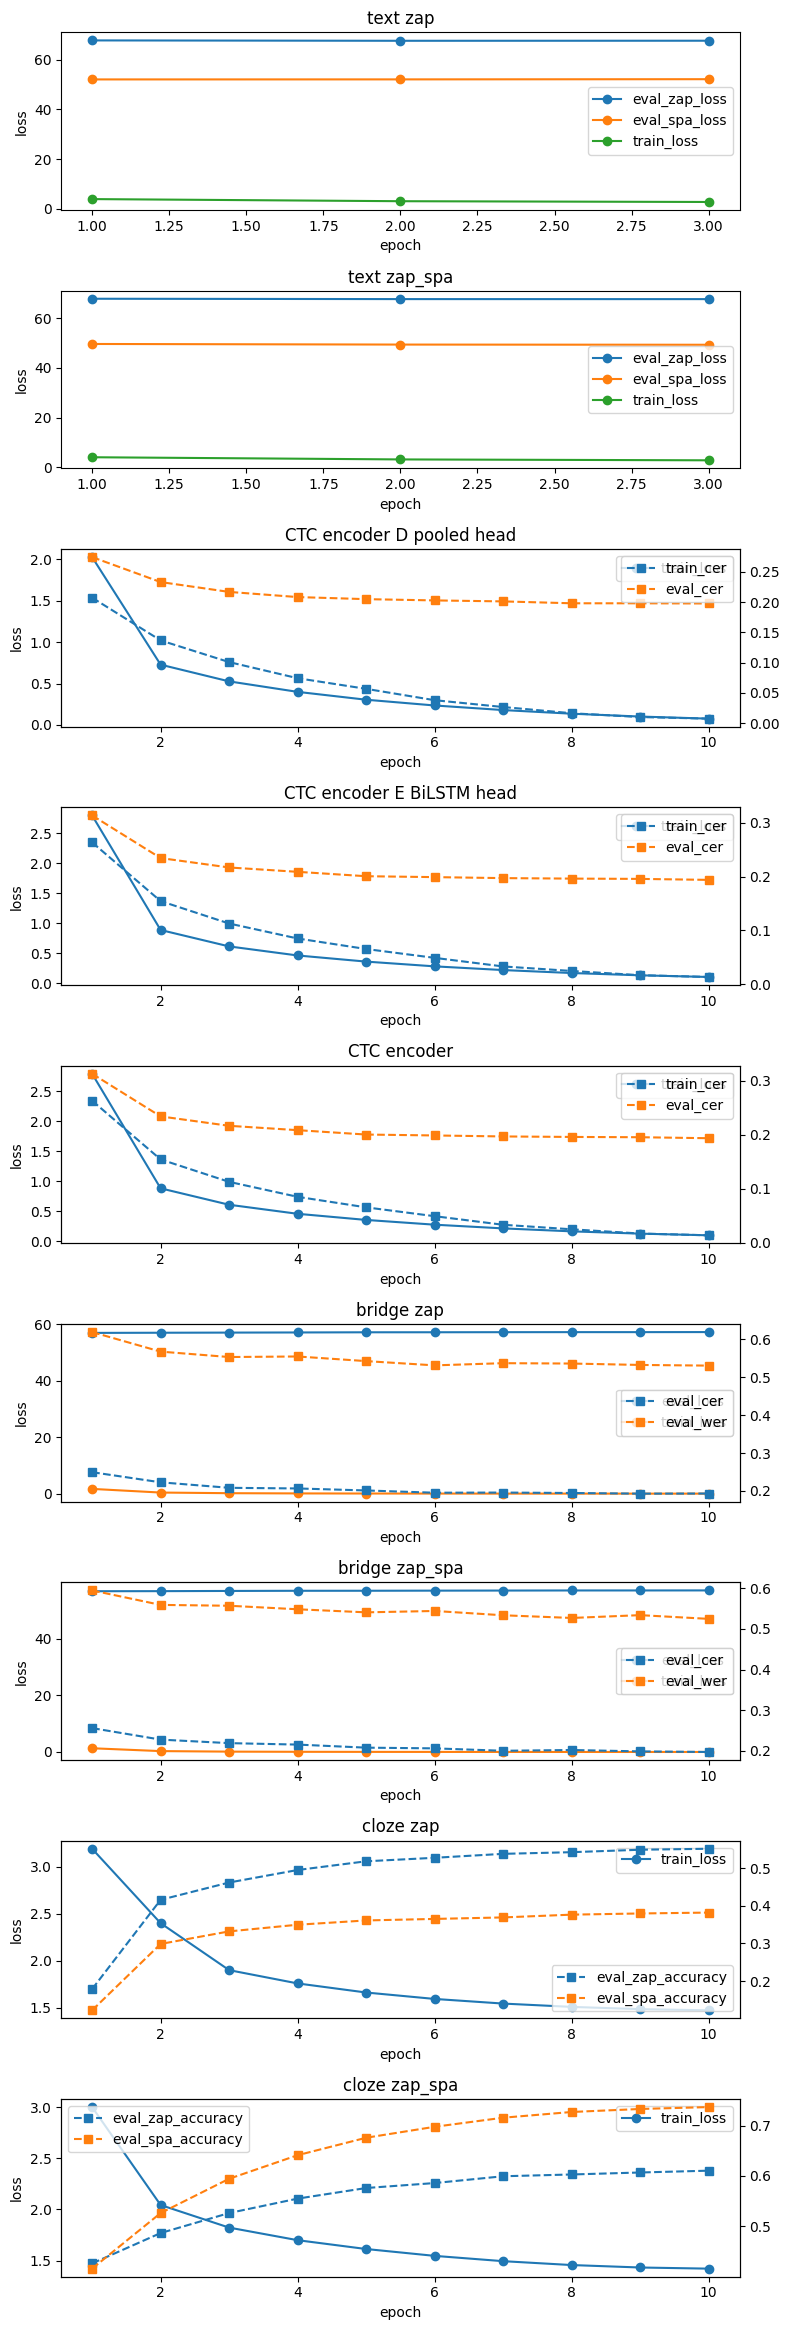

text zap


,eval_zap_loss,eval_spa_loss,train_loss
epoch,,,
1,67.7620,52.0688,3.9309
2,67.6119,52.0845,3.0804
3,67.6374,52.1626,2.7698


text zap_spa


,eval_zap_loss,eval_spa_loss,train_loss
epoch,,,
1,67.7627,49.6007,4.1131
2,67.6212,49.3595,3.2384
3,67.6107,49.2839,2.8820


CTC encoder D pooled head


...

,eval_cer,eval_loss,eval_wer,train_loss
epoch,,,,
1,0.2560,56.7725,0.5948,1.3187
2,0.2277,56.7981,0.5592,0.3120
3,0.2191,56.8690,0.5571,0.1243
4,0.2155,56.9262,0.5484,0.0644
5,0.2079,56.9376,0.5409,0.0363
6,0.2062,56.9758,0.5442,0.0220
7,0.2002,57.0083,0.5336,0.0133
8,0.2022,57.0407,0.5271,0.0078
9,0.1988,57.0463,0.5340,0.0043


cloze zap


,train_loss,eval_zap_accuracy,eval_spa_accuracy
epoch,,,
1,3.1922,0.1785,0.1220
2,2.4011,0.4161,0.2986
3,1.9019,0.4621,0.3320
4,1.7606,0.4954,0.3498
5,1.6641,0.5186,0.3612
6,1.5957,0.5279,0.3652
7,1.5465,0.5384,0.3692
8,1.5113,0.5429,0.3766
9,1.4873,0.5494,0.3798


cloze zap_spa


,train_loss,eval_zap_accuracy,eval_spa_accuracy
epoch,,,
1,2.9997,0.4264,0.4160
2,2.0435,0.4867,0.5264
3,1.8231,0.5264,0.5944
4,1.7002,0.5550,0.6412
5,1.6140,0.5761,0.6758
6,1.5471,0.5859,0.6976
7,1.4953,0.5994,0.7156
8,1.4575,0.6030,0.7270
9,1.4336,0.6069,0.7330


In [25]:
import matplotlib.pyplot as plt


CURVE_METRICS = ('loss', 'cer', 'wer', 'accuracy')


def curve_frame(history):
    """One row per epoch: mean train loss and the evaluation metrics, from a Trainer log or a manual history."""
    rows = {}
    for entry in history:
        if 'train_runtime' in entry:  # the Trainer's end-of-training summary, not an epoch
            continue
        epoch = math.ceil(entry.get('epoch', 0))
        row = rows.setdefault(epoch, {'epoch': epoch, 'step_losses': []})
        for key, value in entry.items():
            if key == 'loss':
                row['step_losses'].append(value)
            elif key.startswith(('eval_', 'train_')) and key.endswith(CURVE_METRICS):
                row[key] = value
    frame = pd.DataFrame(rows.values()).sort_values('epoch')
    if frame['step_losses'].map(len).any():
        frame['train_loss'] = frame['step_losses'].map(lambda v: float(np.mean(v)) if v else np.nan)
    return frame.drop(columns='step_losses').query('epoch > 0').set_index('epoch')


if not curves:
    raise RuntimeError('No training histories yet: run Parts 1-5 first.')
fig, axes = plt.subplots(len(curves), 1, figsize=(8, 2.6 * len(curves)), squeeze=False)
for ax, (name, history) in zip(axes[:, 0], curves.items()):
    frame = curve_frame(history)
    loss_columns = [c for c in frame if c.endswith('loss')]
    metric_columns = [c for c in frame if not c.endswith('loss')]
    frame[loss_columns].plot(ax=ax, marker='o')
    ax.set_title(name)
    ax.set_ylabel('loss')
    if metric_columns:
        frame[metric_columns].plot(ax=ax.twinx(), marker='s', linestyle='--')
plt.tight_layout()
plt.show()
for name, history in curves.items():
    print(name)
    display(curve_frame(history).round(4))

## Test evaluation

In [26]:
# Final test evaluation — run after Parts 1-5 (Parts 4 and 5 can be skipped). Scores are broken down by language so the effect of the
# Zapotec embeddings on Zapotec lines is visible.
references = [str(t or '').strip() for t in ds['test']['text']]


def prediction_frame(predictions):
    return pd.DataFrame({
        'id': ds['test']['id'],
        'doc_id': ds['test']['doc_id'],
        'reference': references,
        'prediction': [p.strip() for p in predictions],
        'language': ds['test']['language']
    })


def generated_text(result):
    pred_ids = result.predictions
    if isinstance(pred_ids, tuple):
        pred_ids = pred_ids[0]
    return processor.batch_decode(pred_ids, skip_special_tokens=True)


def scores_by_language(name, df):
    rows = []
    for language, group in [('all', df), *df.groupby('language')]:
        rows.append({'model': name, 'language': language, 'lines': len(group),
                     'cer': cer(list(group['reference']), list(group['prediction'])),
                     'wer': wer(list(group['reference']), list(group['prediction']))})
    return rows


test_frames = {}
if 'baseline_result' in globals():
    test_frames['pretrained baseline'] = prediction_frame(generated_text(baseline_result))
test_frames['encoder CTC only'] = prediction_frame(ctc_predict(ctc_model, ds['test'])[0])
for variant, variant_trainer in bridge_trainers.items():
    test_result = variant_trainer.predict(ds['test'], metric_key_prefix='test')
    print(variant, test_result.metrics)
    variant_trainer.save_metrics('test', test_result.metrics)
    test_frames[f'bridge {variant}'] = prediction_frame(generated_text(test_result))
# Parts 4 and 5 leave their test predictions here.
for name, predictions in globals().get('extra_test_predictions', {}).items():
    test_frames[name] = prediction_frame(predictions)

for name, df in test_frames.items():
    path = os.path.join(OUTPUT_DIR, f"test_predictions_{name.replace(' ', '_')}.csv")
    df.to_csv(path, index=False)
    print('Saved predictions:', path)

scores = pd.DataFrame([row for name, df in test_frames.items() for row in scores_by_language(name, df)])
scores.to_csv(os.path.join(OUTPUT_DIR, 'test_scores_by_language.csv'), index=False)
display(scores.pivot(index='model', columns='language', values='cer').round(3))

# The same scores without Za687, to compare with ticha_trocr_evaluation.ipynb: the models there were trained on
# dataset v1.0, whose train split holds the same pages (Th687), so that notebook leaves Za687 out.
COMPARABLE_EXCLUDE = {'Za687'}
comparable = pd.DataFrame([row for name, df in test_frames.items()
                           for row in scores_by_language(name, df[~df['doc_id'].isin(COMPARABLE_EXCLUDE)])])
comparable.to_csv(os.path.join(OUTPUT_DIR, 'test_scores_by_language_without_Za687.csv'), index=False)
print('Without Za687 (comparable with ticha_trocr_evaluation.ipynb):')
display(comparable.pivot(index='model', columns='language', values='cer').round(3))
display(test_frames[f'bridge {DECODER_VARIANTS[0]}'].head(10))

Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.


Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.


Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.


Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.


Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.


...

Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.


Saved predictions: /home/paw/ticha-runs/trocr-modified-aug-reg/test_predictions_pretrained_baseline.csv
Saved predictions: /home/paw/ticha-runs/trocr-modified-aug-reg/test_predictions_encoder_CTC_only.csv
Saved predictions: /home/paw/ticha-runs/trocr-modified-aug-reg/test_predictions_bridge_zap.csv
Saved predictions: /home/paw/ticha-runs/trocr-modified-aug-reg/test_predictions_bridge_zap_spa.csv
Saved predictions: /home/paw/ticha-runs/trocr-modified-aug-reg/test_predictions_CTC_+_cloze_zap.csv
Saved predictions: /home/paw/ticha-runs/trocr-modified-aug-reg/test_predictions_CTC_+_cloze_zap_spa.csv


Without Za687 (comparable with ticha_trocr_evaluation.ipynb):


language,Spanish,Spanish with some Zapotec,Zapotec,all
model,,,,
CTC + cloze zap,0.147,0.220,0.186,0.172
CTC + cloze zap_spa,0.144,0.217,0.185,0.169
bridge zap,0.123,0.216,0.195,0.161
bridge zap_spa,0.124,0.239,0.207,0.169
encoder CTC only,0.147,0.221,0.189,0.173
pretrained baseline,0.659,0.737,0.722,0.692


,id,doc_id,reference,prediction,language
0,SDE693a_p001_l001,SDE693a,Nij guichij Santto Domingo naavilla Guichij lu...,Cuy Luchij Santo Domingo GaVilla Guchij luhuana,Zapotec
1,SDE693a_p001_l002,SDE693a,Anos chij luny cochino lasepeo deAbril de mill...,Nos guey Lunes Cochinij Lao de millbril de mil...,Zapotec
2,SDE693a_p001_l003,SDE693a,ventta Yttres anos Nicachina Yohoo lichy=ij ni...,Sentta Sitnes años Nicachina Gohoa lichij nico...,Zapotec
3,SDE693a_p001_l004,SDE693a,Benij hualachij laaca Guichij Sto domo naavill...,Benj hualachij Laaca Guichij 9 domdo naalilla ...,Zapotec
4,SDE693a_p001_l005,SDE693a,luhuana Pechina teneya ssno de Cafilldo huane ...,Su huana Pechina de naya q. de cavildo huane t...,Zapotec
5,SDE693a_p001_l006,SDE693a,nia qe conavaa laaca Nicolas mendes quela huesala,nia q con alra laaca Nicolas mendes quela huisala,Zapotec
6,SDE693a_p001_l007,SDE693a,chij lao coquij Gouor chela guiropa alcaldes h...,chij Lao Conij Conij chela guiropa alcaldes he...,Zapotec
7,SDE693a_p001_l008,SDE693a,Goca tovij es Crittura de ventta guerij lania ...,Laca dosij esritura de Ventta quierij Lania Co...,Zapotec
8,SDE693a_p001_l009,SDE693a,Pechinatta nij Jiuesa Juo mendes laatto Benij hua,Pechina ttao nij liaeta Juo mendes Laatoo Beni...,Zapotec
9,SDE693a_p001_l010,SDE693a,Lachij Guechij Santto Domo penava ttichatanij ...,Lachij guichij Santto Gemo genavio ticha Lanij...,Zapotec


## Comparison with the run without augmentation

Best validation CER of each image-trained model in both runs (the encoder's best epoch and each bridge's best checkpoint), then the test CER by language when both runs have run their test evaluation. Validation CER chose the checkpoints; the test numbers are reported once.

In [27]:
def best_validation_cer(run_dir):
    rows = {}
    encoder_file = os.path.join(run_dir, 'encoder_ctc', 'encoder_ctc.pt')
    if os.path.exists(encoder_file):
        rows['encoder CTC only'] = torch.load(encoder_file, map_location='cpu')['best_cer']
    for name in sorted(os.listdir(run_dir)):
        state_file = os.path.join(run_dir, name, 'trainer_state.json')
        if name.startswith(('bridge_', 'char_bridge_')) and os.path.exists(state_file):
            rows[name.replace('_', ' ')] = json.load(open(state_file))['best_metric']
    return rows


RUNS = {'no augmentation': DECOUPLED_DIR, 'augmentation': AUG_DIR, 'augmentation + regularized CTC': OUTPUT_DIR}
validation_comparison = pd.DataFrame({run: best_validation_cer(run_dir) for run, run_dir in RUNS.items()
                                      if os.path.isdir(run_dir)})
print('Validation CER (lower is better):')
display(validation_comparison.round(4))

test_scores = [scores.assign(run='augmentation + regularized CTC')]
for run, run_dir in list(RUNS.items())[:2]:
    scores_file = os.path.join(run_dir, 'test_scores_by_language.csv')
    if os.path.exists(scores_file):
        test_scores.append(pd.read_csv(scores_file).assign(run=run))
    else:
        print(f'No test scores in {run_dir} yet: run that notebook\'s test evaluation.')
print('Test CER by language:')
display(pd.concat(test_scores).pivot_table(index='model', columns=['language', 'run'], values='cer').round(3))

Validation CER (lower is better):


,no augmentation,augmentation,augmentation + regularized CTC
encoder CTC only,0.2395,NaN,0.1937
bridge zap,0.2136,NaN,0.1928
bridge zap spa,0.2178,NaN,0.1973
char bridge zap l2r,0.2018,NaN,NaN
char bridge zap r2l,0.2304,NaN,NaN
char bridge zap spa l2r,0.2092,NaN,NaN
char bridge zap spa r2l,0.2654,NaN,NaN


No test scores in /home/paw/ticha-runs/trocr-modified-aug yet: run that notebook's test evaluation.
Test CER by language:


language                                   Spanish                  \
run                 augmentation + regularized CTC no augmentation   
model                                                                
CTC + cloze zap                              0.147           0.195   
CTC + cloze zap_spa                          0.144           0.188   
bridge zap                                   0.123           0.152   
bridge zap_spa                               0.124           0.146   
encoder CTC only                             0.147           0.193   
pretrained baseline                          0.659           0.654   

language                 Spanish with some Zapotec                  \
run                 augmentation + regularized CTC no augmentation   
model                                                                
CTC + cloze zap                              0.220           0.256   
CTC + cloze zap_spa                          0.217           0.249   
bridge zap                                   0.216           0.227   
bridge zap_spa                               0.239           0.251   
encoder CTC only                             0.221           0.257   
pretrained baseline                          0.737           0.735   

language                                   Zapotec                  \
run                 augmentation + regularized CTC no augmentation   
model                                                                
CTC + cloze zap                              0.191           0.225   
CTC + cloze zap_spa                          0.189           0.224   
bridge zap                                   0.201           0.223   
bridge zap_spa                               0.215           0.237   
encoder CTC only                             0.193           0.228   
pretrained baseline                          0.732           0.728   

language                                       all                  
run                 augmentation + regularized CTC no augmentation  
model                                                               
CTC + cloze zap                              0.174           0.216  
CTC + cloze zap_spa                          0.171           0.210  
bridge zap                                   0.164           0.188  
bridge zap_spa                               0.173           0.193  
encoder CTC only                             0.175           0.216  
pretrained baseline                          0.696           0.691

## How to report results

- CER and WER are error rates: **lower is better**.
- State that Th687 was removed from train because it is the same manuscript as Za687 (test), and whether the original/translation pairs were kept (`DROP_TRANSLATION_PAIRS`). Models trained before this fix (`ticha_trocr_finetuning.ipynb` on dataset v1.0) have seen Za687's pages, so compare them with this notebook on the second table, which leaves Za687 out, as `ticha_trocr_evaluation.ipynb` does.
- Validation CER selects the CTC encoder epoch and the bridge checkpoint; the test split is evaluated once, at the end.
- Compare on the same cleaned test set: pretrained baseline, plain fine-tuning (`ticha_trocr_finetuning.ipynb`), encoder CTC only, and the two bridge variants.
- The question this notebook answers is in the **Zapotec** column: does a decoder trained on Zapotec text (`zap`) or on mixed text (`zap_spa`) lower the error on Zapotec lines, and what does it cost on Spanish lines?
- Report the decoder perplexities from Part 1 next to the CER: they show how much the text alone taught the decoder.
- State that the output vocabulary was restricted to tokens seen in the training text plus single characters, and that the printed corpus was split into Zapotec and Spanish with a character n-gram classifier trained on the words Ticha marks as Zapotec in Córdova's grammar.
- Parts 4 and 5 answer a second question: does predicting characters, with context from both sides, help more than word pieces? Compare `char l2r` with `bridge` (characters vs word pieces), `char l2r+r2l` with `char l2r` (adding the right-hand context), and `CTC + cloze` with `encoder CTC only`.
- The reranking weight `w` and the cloze weight `β` were chosen on validation; report them. The cloze correction fixes substituted characters only.
- Not done here, for later: permutation language modeling (PARSeq), where one decoder is trained on random prediction orders so it can use context on both sides directly.
- **Augmentation:** this run differs from the run without augmentation only in the image stages (Parts 2, 3 and, if run, 4.2), which trained on the original + augmented train lines with the same settings and number of epochs (so about 5× the steps). The text-only models are the same files. Report both runs' validation and test CER from the last cells, and the Part 2 train/validation CER gap of both, which shows how much augmentation reduced the encoder's overfitting.
- **Regularized CTC encoder:** report the first attempt (all three changes at once underfit: CER 0.85 after 2 epochs), the ablation table, the chosen variant (`CTC_CHOICE`) and why, and the early stop (patience 3). Compare its Part 2 train/validation CER gap and best validation CER with both earlier runs; the bridges are the same recipe in all three.